# Clasificación de personajes de Los Simpson con ResNet-50

Evaluación Sumativa 2 — Deep Learning (AVY1103). Este notebook contiene **todo el flujo del modelo ResNet-50** (torchvision, preentrenado en ImageNet): configuración, carga y exploración de los datos, preprocesamiento, arquitectura, entrenamiento con *fine-tuning*, evaluación, costo computacional y exportación.

Es el segundo modelo del proyecto; el primero es YOLO11m-cls (`yolo11.ipynb`). Ambos usan **la misma división de datos, el mismo preprocesamiento de evaluación y las mismas métricas**, para que la comparación sea justa.

**Cómo usarlo** (detalles en `informe_resnet50.md`)

1. Revisar la sección 0.1 (hiperparámetros) y ajustar lo que se quiera probar.
2. Ejecutar todas las celdas en orden (*Run All*). Cada ejecución crea una carpeta nueva `resultados/resnet50/testN/` con todo lo generado.
3. Para reevaluar una prueba ya entrenada sin volver a entrenar, definir `TEST_A_EVALUAR = "testN"` en la sección 0.1.
4. **Datos:** se usa el dataset dividido de `dataset/simpsons_split/`, que crea `yolo11.ipynb`. Este notebook no vuelve a dividir: verifica que la carpeta coincida con su manifiesto `division.csv`.
5. **Aplicación web:** para llevar una prueba a la web, ejecutar `python exportar_modelo.py resnet50 testN` (o usar `EXPORTAR_A_APP = True`). Queda en `app/models/resnet50_testN/` y aparece en el selector de modelos.

**Contenido de cada carpeta `resultados/resnet50/testN/`**

| Archivo | Contenido |
|---|---|
| `weights/best.pt`, `weights/last.pt` | Modelo completo del mejor peso (según validación) y de la última época |
| `configuracion.json` | Datos, preprocesamiento, hiperparámetros, entorno (versiones y GPU), fechas y duración |
| `resnet50_copia.ipynb` | Copia del notebook al momento de iniciar la prueba |
| `entrenamiento.log` | Registro de texto del entrenamiento (una línea por época) |
| `historial.csv` | Métricas por época: loss y accuracy de entrenamiento y validación, learning rate y etapa |
| `division.csv`, `clases.json` | Imágenes de cada subconjunto (rutas dentro de `dataset/simpsons_split/`) y orden de clases del modelo |
| `metricas_test.json`, `reporte_clasificacion.csv` | Métricas globales y por clase en el conjunto de prueba |
| `matriz_confusion_test.csv`, `confusiones_frecuentes.csv` | Matriz de confusión (conteos) y pares más confundidos |
| `costo_computacional.json` | Parámetros, GFLOPs, tamaño del peso y latencia de inferencia |
| `graficos/` | Todos los gráficos del notebook en PNG |
| `resumen.md` | Resumen legible de la prueba |

Las decisiones sobre los datos (filtro de clases, duplicados, receta de la división) están en `informe_yolo11.md`; las de este modelo, en `informe_resnet50.md`, cuyo historial de pruebas se actualiza al final de cada ejecución.

## 0. Configuración

Si el entorno aún no tiene las dependencias, ejecutar una vez la celda siguiente quitando el `#`. Es el mismo entorno de `yolo11.ipynb`: PyTorch debe instalarse con soporte CUDA (ver `informe_yolo11.md`, sección 2). **El notebook entrena solo en GPU:** si PyTorch no detecta CUDA, se detiene en la sección 0.2 con un error en vez de entrenar en CPU.

In [1]:
# %pip install torch torchvision scikit-learn seaborn pandas matplotlib

In [2]:
import json
import os
import platform
import random
import re
import shutil
import sys
import time
from copy import deepcopy
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torch.utils.flop_counter import FlopCounterMode
from torchvision import transforms
from torchvision.models import ResNet50_Weights, resnet50

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

### 0.1 Parámetros de la prueba

Todos los parámetros de una prueba están en esta celda. Se copian automáticamente a `configuracion.json` dentro de la carpeta de la prueba.

In [3]:
# Rutas (el notebook se ejecuta desde la carpeta DeepLearningModelos/)
BASE_DIR = Path.cwd()
# Dataset dividido train/val/test con su manifiesto division.csv (lo crea yolo11.ipynb; es la misma división)
SPLIT_DIR = BASE_DIR / "dataset" / "simpsons_split"
RESULTADOS_DIR = BASE_DIR / "resultados" / "resnet50"  # una subcarpeta testN por prueba
APP_DIR = BASE_DIR / "app"
INFORME_PATH = BASE_DIR / "informe_resnet50.md"

# Modelo base: ResNet-50 de torchvision preentrenada en ImageNet-1k (pesos V2: 80,9 % top-1)
MODELO_BASE = "resnet50"
NOMBRE_MODELO = "ResNet-50"
PESOS_PREENTRENADOS = ResNet50_Weights.IMAGENET1K_V2

# Preprocesamiento de evaluación (también lo usa la aplicación web, a través de modelo.json)
PREPROCESAMIENTO = {
    "imgsz": 224,
    "redimension": "recorte_central",  # lado corto a imgsz y recorte central, igual que YOLO11 y la app
    # Media y desviación de ImageNet: es la escala de entrada que esperan los pesos preentrenados
    "normalizacion": {"media": [0.485, 0.456, 0.406], "desviacion": [0.229, 0.224, 0.225]},
}

# Hiperparámetros
HIPERPARAMETROS = {
    "imgsz": PREPROCESAMIENTO["imgsz"],  # no editar aquí: el tamaño se cambia en PREPROCESAMIENTO["imgsz"]
    "epochs": 50,
    "patience": 10,              # detención anticipada tras 7 épocas sin mejorar la accuracy de validación
    "batch": 64,                # bajar a 32 si aparece "CUDA out of memory"
    "epocas_congeladas": 3,     # etapa 1: solo se entrena la cabeza (0 = fine-tuning completo desde el inicio)
    "optimizer": "AdamW",       # "AdamW" o "SGD" (con momentum 0,9)
    "lr_cabeza": 1e-3,
    "lr_backbone": 1e-4,        # learning rate discriminativo: el backbone preentrenado se ajusta 10 veces más lento
    "lrf": 0.01,                # learning rate final = lr inicial * lrf (decaimiento coseno)
    "warmup_epochs": 1,
    "weight_decay": 1e-2,
    "dropout": 0.2,             # dropout antes de la capa lineal de la cabeza
    "label_smoothing": 0.1,
    "peso_clases": 0.0,         # ponderación por clase: peso ∝ (1 / frecuencia) ** peso_clases (0 = desactivada)
    "amp": True,                # precisión mixta
    "workers": 8,               # procesos que cargan y aumentan las imágenes (0 = en el proceso principal)
    "seed": 42,
    "deterministic": True,
    # Aumentación de datos (la misma que en yolo11.ipynb)
    "fliplr": 0.5,              # giro horizontal
    "scale": 0.5,               # zoom: recorte aleatorio de 50 % a 100 % del área
    "auto_augment": "randaugment",  # "randaugment", "autoaugment", "trivialaugment", "augmix" o None
    "erasing": 0.4,             # borrado aleatorio de un rectángulo
}

# Evaluación
EVALUACION = {
    "muestra_train_por_epoca": 1500,  # imágenes de train para medir loss/accuracy de entrenamiento sin aumentación
    "lote_inferencia": 128,
    "repeticiones_latencia": 50,
}

# Reevaluar una prueba existente sin entrenar (p. ej. "test3"); None = entrenar una prueba nueva
TEST_A_EVALUAR = None

# Exportar esta prueba a la aplicación web (app/models/resnet50_testN/).
# También se puede hacer después, sin el notebook: python exportar_modelo.py resnet50 testN
EXPORTAR_A_APP = False

### 0.2 Entorno, semillas y carpeta de la prueba

Se fijan las semillas para que el entrenamiento sea reproducible (salvo pequeñas diferencias numéricas propias de la GPU). El dispositivo es siempre la GPU 0: si no se detecta CUDA, la celda se detiene con un error. La carpeta `testN` se numera automáticamente; si la última prueba quedó sin peso (`best.pt`), se reutiliza su número.

Los procesos que cargan las imágenes (*workers* del `DataLoader`) se crean con el método `fork`: desde Python 3.14 el método por defecto en Linux es `forkserver`, con el que esos procesos no encuentran las clases definidas en este notebook.

In [4]:
SEMILLA = HIPERPARAMETROS["seed"]
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.backends.cudnn.deterministic = HIPERPARAMETROS["deterministic"]
torch.backends.cudnn.benchmark = not HIPERPARAMETROS["deterministic"]

assert torch.cuda.is_available(), (
    "No se detectó una GPU con CUDA. Este notebook entrena solo en GPU: revisar que el kernel sea el de .venv "
    "y la sección 2.12 de informe_yolo11.md."
)
DEVICE = torch.device("cuda:0")  # GPU 0 (RTX 4060): el entrenamiento y la evaluación nunca caen a CPU
torch.cuda.manual_seed_all(SEMILLA)
IMGSZ = PREPROCESAMIENTO["imgsz"]
CONTEXTO_WORKERS = "fork" if HIPERPARAMETROS["workers"] > 0 else None


def info_entorno():
    return {
        "python": platform.python_version(),
        "sistema": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "cuda": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0),
        "vram_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1),
        "cpus": os.cpu_count(),
    }


def preparar_carpeta_test(directorio):
    # Devuelve (nombre, ruta) de la prueba: reutiliza la última si quedó sin best.pt
    directorio.mkdir(parents=True, exist_ok=True)
    pruebas = sorted(
        (int(m.group(1)), p)
        for p in directorio.iterdir()
        if p.is_dir() and (m := re.fullmatch(r"test(\d+)", p.name))
    )
    if pruebas and not (pruebas[-1][1] / "weights" / "best.pt").exists():
        numero, ruta = pruebas[-1]
        shutil.rmtree(ruta)
    else:
        numero = pruebas[-1][0] + 1 if pruebas else 1
        ruta = directorio / f"test{numero}"
    ruta.mkdir(parents=True)
    return ruta.name, ruta


def guardar_json(datos, ruta):
    ruta.write_text(json.dumps(datos, indent=2, ensure_ascii=False, default=str), encoding="utf-8")


def guardar_figura(fig, nombre):
    GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(GRAFICOS_DIR / f"{nombre}.png", bbox_inches="tight", dpi=150)


def miles(n):
    # Formato con punto de miles, como en castellano: 20933 -> "20.933"
    return f"{int(n):,}".replace(",", ".")


def nombre_visible(clase):
    return " ".join(p.capitalize() for p in clase.split("_"))


ENTORNO = info_entorno()

if TEST_A_EVALUAR is None:
    NOMBRE_TEST, TEST_DIR = preparar_carpeta_test(RESULTADOS_DIR)
else:
    NOMBRE_TEST, TEST_DIR = TEST_A_EVALUAR, RESULTADOS_DIR / TEST_A_EVALUAR
    assert (TEST_DIR / "weights" / "best.pt").exists(), f"No existe {TEST_DIR / 'weights' / 'best.pt'}"
GRAFICOS_DIR = TEST_DIR / "graficos"
WEIGHTS_DIR = TEST_DIR / "weights"

print(f"Prueba: {NOMBRE_TEST} -> {TEST_DIR}")
print(f"Modo: {'entrenamiento nuevo' if TEST_A_EVALUAR is None else 'reevaluación sin entrenar'}")
pd.Series(ENTORNO, name="entorno").to_frame()

Prueba: test2 -> /home/felipe/Escritorio/6° semestre/deeplearning/ev2/DeepLearningModelos/resultados/resnet50/test2
Modo: entrenamiento nuevo


,entorno
python,3.14.4
sistema,Linux-7.0.0-38-generic-x86_64-desconocido-with...
torch,2.14.1+cu130
torchvision,0.29.1+cu130
cuda,13.0
gpu,NVIDIA GeForce RTX 4060 Laptop GPU
vram_gb,8.2
cpus,20


## 1. Carga y exploración del conjunto de datos

El dataset *The Simpsons Characters Data* trae 42 personajes (20.933 imágenes, más una copia anidada idéntica que se descarta). La exploración completa, la detección de duplicados y la creación de la división están en `yolo11.ipynb` (secciones 1 y 2) y en `informe_yolo11.md` (secciones 3 a 5). Aquí se parte del **manifiesto** `dataset/simpsons_split/division.csv`, que registra cada imagen original con su clase, su huella MD5 y su destino: `train`, `val`, `test`, `excluida` (clase con 100 imágenes o menos) o `duplicada` (copia repetida).

In [5]:
MANIFIESTO = SPLIT_DIR / "division.csv"
assert MANIFIESTO.exists(), (
    f"No se encontró {MANIFIESTO.relative_to(BASE_DIR)}. Crear la división ejecutando yolo11.ipynb "
    "(secciones 1 y 2) o copiar dataset/simpsons_split/ (ver informe_yolo11.md, sección 2.3)."
)
manifiesto = pd.read_csv(MANIFIESTO)
unicas = manifiesto[manifiesto["subconjunto"] != "duplicada"]

print(f"Imágenes originales en el manifiesto: {miles(len(manifiesto))} ({manifiesto['clase'].nunique()} clases)")
print(f"Imágenes únicas (sin duplicados MD5):  {miles(len(unicas))}")
display(manifiesto["subconjunto"].value_counts().rename("imágenes").rename_axis("destino").to_frame())

Imágenes originales en el manifiesto: 20.933 (42 clases)
Imágenes únicas (sin duplicados MD5):  20.927


,imágenes
destino,
train,14128
val,3028
test,3028
excluida,743
duplicada,6


### 1.1 Distribución de imágenes por clase

El dataset está fuertemente desbalanceado. En azul, los 25 personajes con más de 100 imágenes que usa el modelo; en naranjo, los excluidos. Se usa escala logarítmica para que se vean todas las clases.

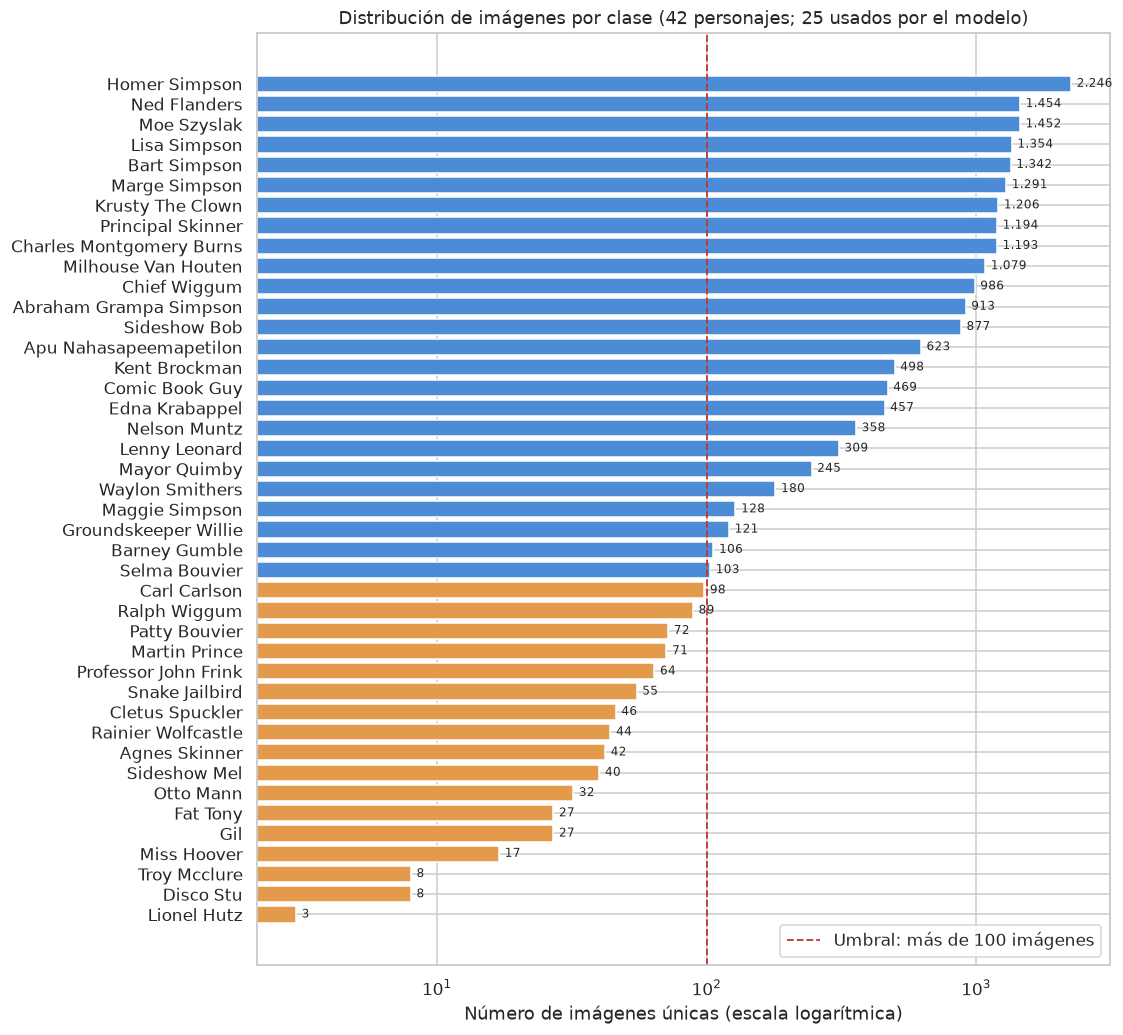

Clases del modelo: 25  |  excluidas: 17
Máximo: 2.246 (homer_simpson)  |  Mínimo: 103 (selma_bouvier)
Razón de desbalance en las clases del modelo (máx/mín): 22x


In [6]:
conteo = unicas["clase"].value_counts().sort_values()
CLASES = sorted(manifiesto.loc[manifiesto["subconjunto"].isin(["train", "val", "test"]), "clase"].unique())
INDICE = {clase: i for i, clase in enumerate(CLASES)}  # orden alfabético = índice de cada clase en el modelo

fig, ax = plt.subplots(figsize=(10, 11))
colores = ["#4C8BD6" if c in INDICE else "#E39B4B" for c in conteo.index]
ax.barh([nombre_visible(c) for c in conteo.index], conteo.values, color=colores)
ax.axvline(100, color="#C0392B", ls="--", lw=1.2, label="Umbral: más de 100 imágenes")
for i, n in enumerate(conteo.values):
    ax.text(n * 1.05, i, miles(n), va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Número de imágenes únicas (escala logarítmica)")
ax.set_title(f"Distribución de imágenes por clase ({len(conteo)} personajes; {len(CLASES)} usados por el modelo)")
ax.legend(loc="lower right")
guardar_figura(fig, "01_distribucion_clases")
plt.show()

conteo_modelo = conteo[conteo.index.isin(CLASES)]
print(f"Clases del modelo: {len(CLASES)}  |  excluidas: {len(conteo) - len(CLASES)}")
print(f"Máximo: {miles(conteo_modelo.max())} ({conteo_modelo.idxmax()})  |  Mínimo: {miles(conteo_modelo.min())} ({conteo_modelo.idxmin()})")
print(f"Razón de desbalance en las clases del modelo (máx/mín): {conteo_modelo.max() / conteo_modelo.min():.0f}x")

### 1.2 Dimensiones originales de las imágenes

Se analizan las imágenes de las 25 clases del modelo. No tienen un tamaño uniforme, por lo que es necesario estandarizar la resolución antes de entrenar (sección 3).

,count,mean,std,min,25%,50%,75%,max
ancho,20184.0,408.06,149.52,256.00,288.00,320.00,576.00,1912.00
alto,20184.0,416.58,62.81,256.00,379.00,432.00,480.00,1072.00
relacion_aspecto,20184.0,0.99,0.36,0.29,0.67,0.89,1.33,3.57


Modos de color: {'RGB': 20184}
Resoluciones más frecuentes:


,,imágenes
ancho,alto,
320,480,2917
288,432,2831
640,480,2061
576,432,1755
288,416,1680
312,352,1648
576,416,1204
624,352,855


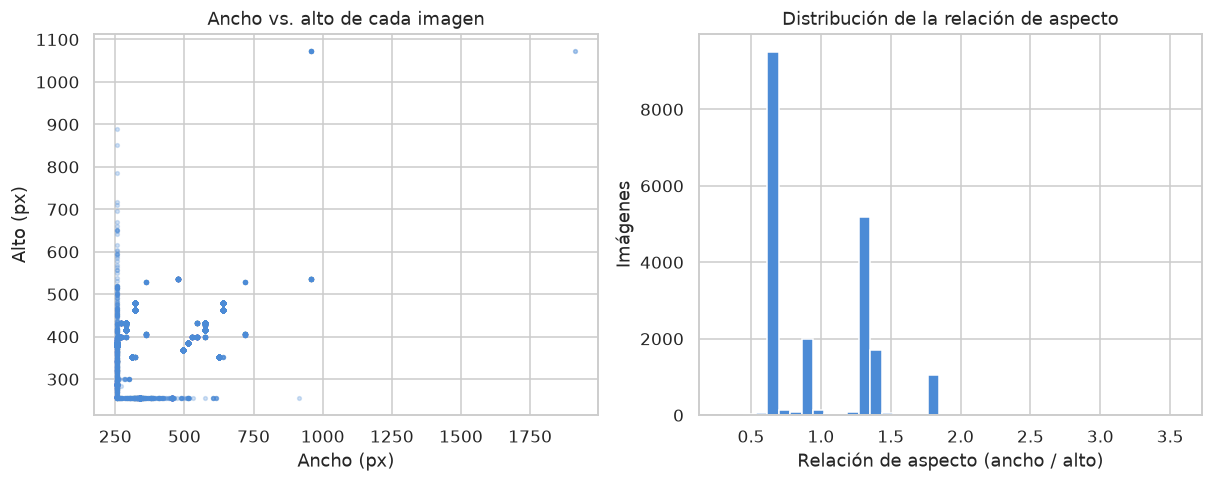

In [7]:
division = manifiesto[manifiesto["subconjunto"].isin(["train", "val", "test"])].reset_index(drop=True)
division["ruta"] = [SPLIT_DIR / r for r in division["ruta_division"]]


def leer_dimensiones(ruta):
    with Image.open(ruta) as im:
        return (*im.size, im.mode)


dimensiones = pd.DataFrame([leer_dimensiones(r) for r in division["ruta"]], columns=["ancho", "alto", "modo"])
dimensiones["relacion_aspecto"] = dimensiones["ancho"] / dimensiones["alto"]

display(dimensiones[["ancho", "alto", "relacion_aspecto"]].describe().round(2).T)
print("Modos de color:", dimensiones["modo"].value_counts().to_dict())
print("Resoluciones más frecuentes:")
display(dimensiones.groupby(["ancho", "alto"]).size().sort_values(ascending=False).head(8).rename("imágenes").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(dimensiones["ancho"], dimensiones["alto"], s=6, alpha=0.25, color="#4C8BD6")
axes[0].set(xlabel="Ancho (px)", ylabel="Alto (px)", title="Ancho vs. alto de cada imagen")
axes[1].hist(dimensiones["relacion_aspecto"], bins=40, color="#4C8BD6")
axes[1].set(xlabel="Relación de aspecto (ancho / alto)", ylabel="Imágenes", title="Distribución de la relación de aspecto")
guardar_figura(fig, "02_dimensiones")
plt.show()

### 1.3 Ejemplos de imágenes

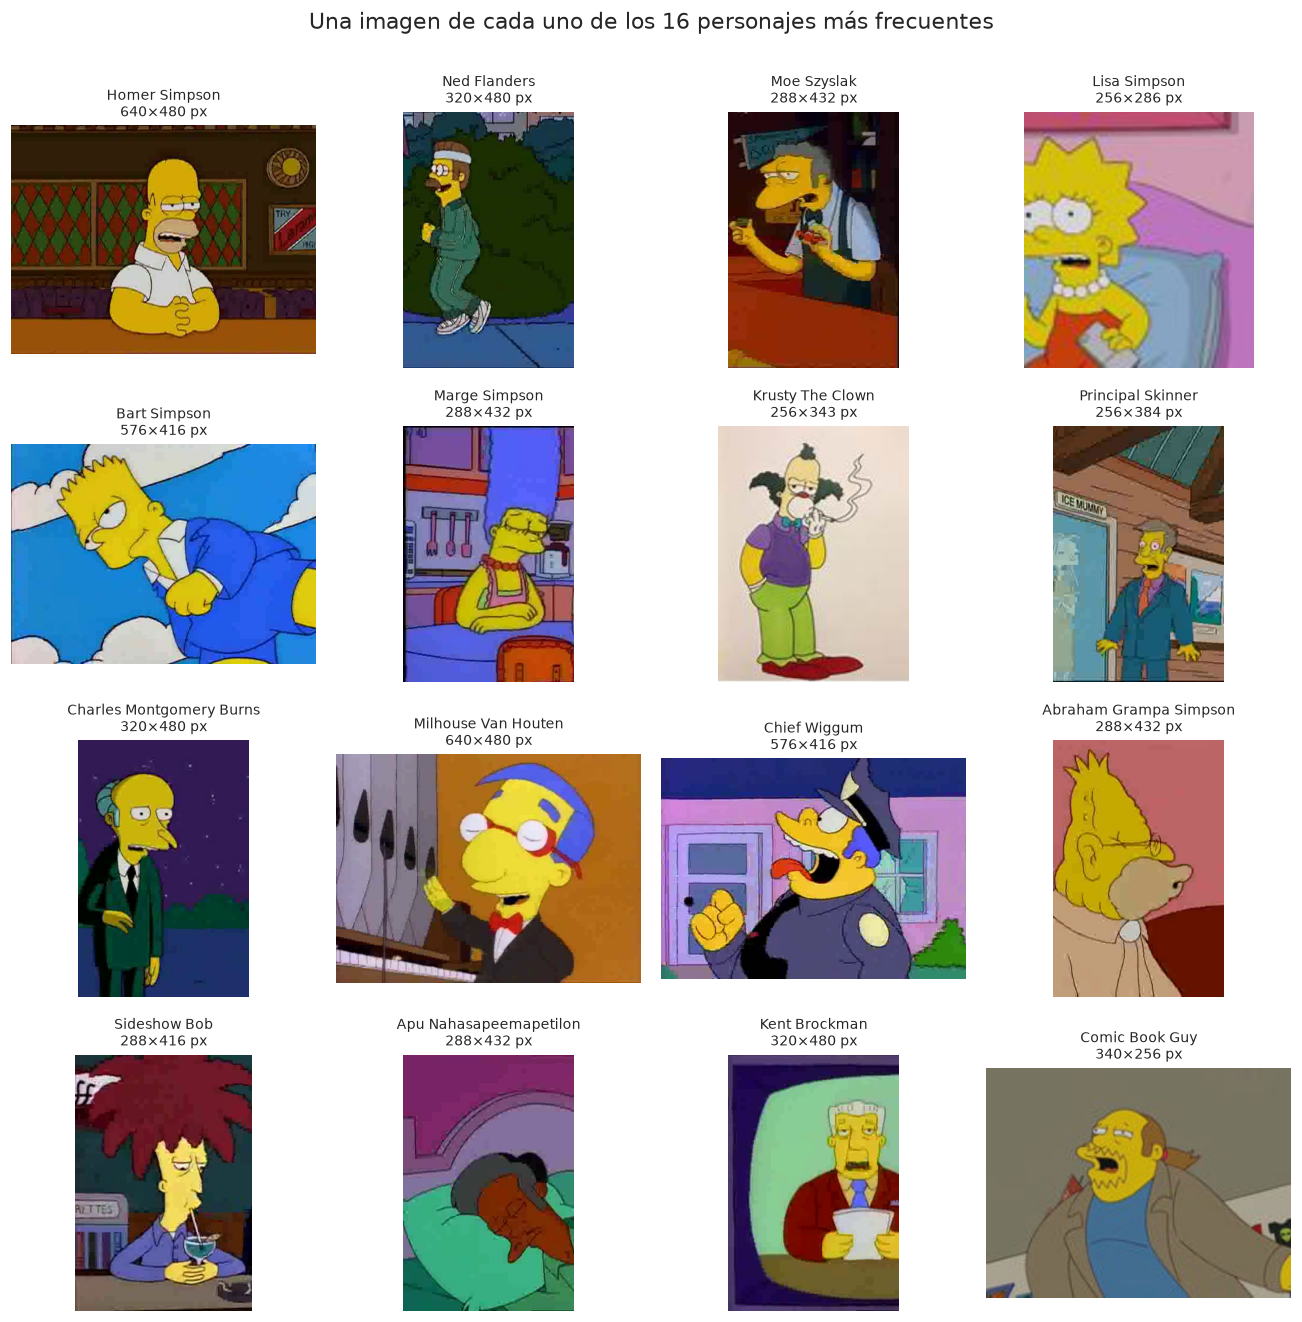

In [8]:
clases_ejemplo = conteo_modelo.sort_values(ascending=False).index[:16]
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for ax, clase in zip(axes.flat, clases_ejemplo):
    fila = division[division["clase"] == clase].sample(1, random_state=SEMILLA).iloc[0]
    imagen = Image.open(fila["ruta"]).convert("RGB")
    ax.imshow(imagen)
    ax.set_title(f"{nombre_visible(clase)}\n{imagen.size[0]}×{imagen.size[1]} px", fontsize=9)
    ax.axis("off")
fig.suptitle("Una imagen de cada uno de los 16 personajes más frecuentes", y=1.0)
fig.tight_layout()
guardar_figura(fig, "03_ejemplos")
plt.show()

## 2. División en entrenamiento, validación y prueba

Se usa **la misma división que YOLO11m-cls**, creada por `yolo11.ipynb`:

- **Proporciones:** 70 % entrenamiento, 15 % validación y 15 % prueba.
- **Estratificada:** cada subconjunto mantiene la proporción de imágenes de cada personaje.
- **Reproducible:** semilla fija (42).
- **Validación** se usa para elegir el mejor peso y para la detención anticipada; **prueba** solo se usa al final para medir la generalización.

Este notebook **no vuelve a dividir**: verifica que cada imagen del manifiesto esté en su carpeta y que no sobren archivos, de modo que ResNet-50 y YOLO11 se entrenen y evalúen con exactamente las mismas imágenes.

In [9]:
faltantes = [r for r in division["ruta"] if not r.exists()]
assert not faltantes, f"Faltan {len(faltantes)} imágenes en {SPLIT_DIR.relative_to(BASE_DIR)}/, p. ej. {faltantes[:3]}"

for s in ["train", "val", "test"]:
    carpetas = sorted(d.name for d in (SPLIT_DIR / s).iterdir() if d.is_dir())
    assert carpetas == CLASES, f"Las carpetas de {s}/ no coinciden con las clases del manifiesto"
    n_archivos = sum(1 for p in (SPLIT_DIR / s).rglob("*") if p.is_file())
    n_manifiesto = int((division["subconjunto"] == s).sum())
    assert n_archivos == n_manifiesto, f"{s}/ tiene {n_archivos} archivos y el manifiesto {n_manifiesto}"

train_df, val_df, test_df = (division[division["subconjunto"] == s].reset_index(drop=True) for s in ["train", "val", "test"])

tabla_division = division.pivot_table(index="clase", columns="subconjunto", values="archivo", aggfunc="count")
tabla_division = tabla_division[["train", "val", "test"]]
tabla_division["total"] = tabla_division.sum(axis=1)

print(f"División verificada: {SPLIT_DIR.relative_to(BASE_DIR)}/ coincide con su manifiesto.")
for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{nombre:>5}: {miles(len(d)):>6} imágenes ({len(d) / len(division):.1%})")
display(tabla_division.sort_values("total", ascending=False))

División verificada: dataset/simpsons_split/ coincide con su manifiesto.
train: 14.128 imágenes (70.0%)
  val:  3.028 imágenes (15.0%)
 test:  3.028 imágenes (15.0%)


subconjunto,train,val,test,total
clase,,,,
homer_simpson,1572,337,337,2246
ned_flanders,1018,218,218,1454
moe_szyslak,1016,218,218,1452
lisa_simpson,948,203,203,1354
bart_simpson,939,202,201,1342
marge_simpson,904,193,194,1291
krusty_the_clown,844,181,181,1206
principal_skinner,836,179,179,1194
charles_montgomery_burns,835,179,179,1193


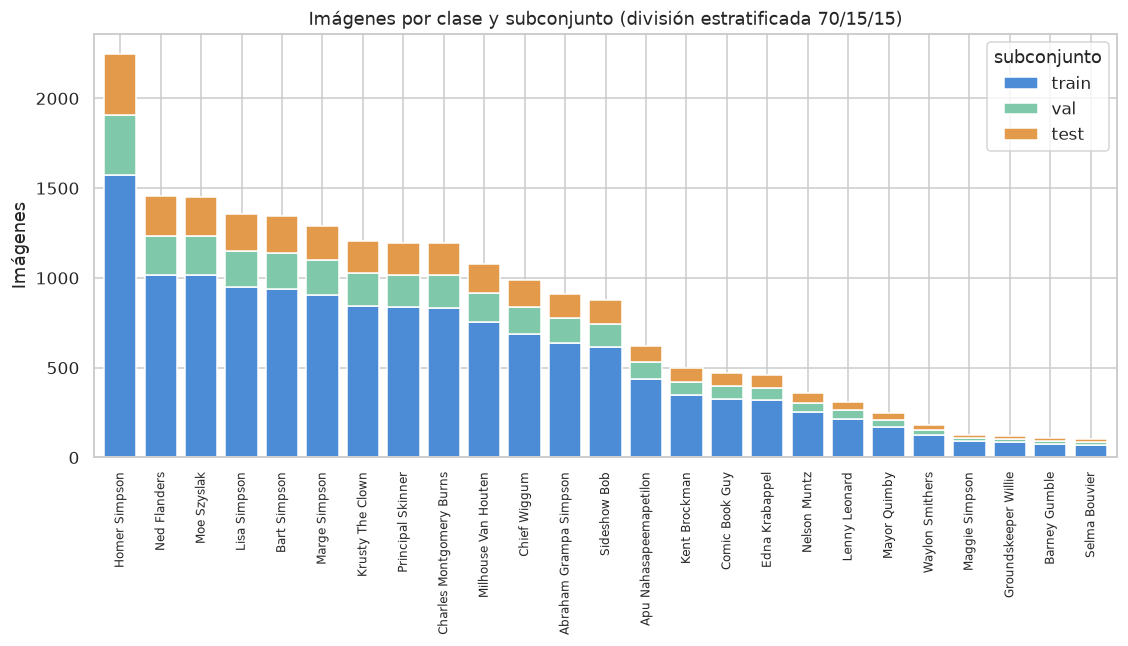

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))
orden = tabla_division.sort_values("total", ascending=False)
orden[["train", "val", "test"]].rename(index=nombre_visible).plot.bar(
    stacked=True, ax=ax, color=["#4C8BD6", "#7FC8A9", "#E39B4B"], width=0.8
)
ax.set(ylabel="Imágenes", xlabel="", title="Imágenes por clase y subconjunto (división estratificada 70/15/15)")
ax.tick_params(axis="x", labelsize=8)
guardar_figura(fig, "04_division")
plt.show()

## 3. Preprocesamiento y aumentación de imágenes

**Entrenamiento** (transformaciones aleatorias en cada época, las mismas de `yolo11.ipynb`):

1. `RandomResizedCrop(224, scale=(0.5, 1.0))`: recorta una región aleatoria de entre 50 % y 100 % del área y la lleva a 224×224 px. Equivale a un **zoom** aleatorio y además **estandariza la resolución**.
2. `RandomHorizontalFlip(p=0.5)`: **giro** horizontal. No se usa giro vertical, porque los personajes nunca aparecen de cabeza.
3. `RandAugment`: aplica operaciones aleatorias como **rotación**, traslación, cizalle, brillo, contraste, nitidez, ecualización y posterización.
4. `ToTensor()`: convierte a tensor y **normaliza los píxeles a [0, 1]** (divide por 255).
5. `Normalize(media, desviación de ImageNet)`: **diferencia con YOLO11**, que se queda en [0, 1]. Centra cada canal con la media y la desviación de los píxeles de ImageNet, que es la escala con la que se entrenaron los pesos preentrenados; sin este paso, las primeras capas recibirían valores en un rango distinto al que conocen.
6. `RandomErasing(p=0.4)`: borra un rectángulo aleatorio, lo que obliga al modelo a no depender de una sola zona de la imagen.

**Validación, prueba e inferencia** (determinista): redimensiona el lado corto a 224 px (conserva la relación de aspecto), recorta el centro a 224×224, escala a [0, 1] y normaliza con ImageNet. Es el mismo recorte que usan YOLO11 y la aplicación web, que lee la normalización desde el `modelo.json` del modelo exportado.

In [11]:
NORMALIZACION = PREPROCESAMIENTO["normalizacion"]
POLITICAS_AUMENTACION = {
    "randaugment": transforms.RandAugment,
    "autoaugment": transforms.AutoAugment,
    "trivialaugment": transforms.TrivialAugmentWide,
    "augmix": transforms.AugMix,
}


def crear_aumentacion(h, imgsz):
    politica = [POLITICAS_AUMENTACION[h["auto_augment"]]()] if h["auto_augment"] else []
    return transforms.Compose(
        [
            transforms.RandomResizedCrop(imgsz, scale=(1.0 - h["scale"], 1.0)),
            transforms.RandomHorizontalFlip(h["fliplr"]),
            *politica,
            transforms.ToTensor(),
            transforms.Normalize(NORMALIZACION["media"], NORMALIZACION["desviacion"]),
            transforms.RandomErasing(h["erasing"]),
        ]
    )


def crear_transformacion_eval(preprocesamiento):
    imgsz, norm = preprocesamiento["imgsz"], preprocesamiento["normalizacion"]
    return transforms.Compose(
        [
            transforms.Resize(imgsz),
            transforms.CenterCrop(imgsz),
            transforms.ToTensor(),
            transforms.Normalize(norm["media"], norm["desviacion"]),
        ]
    )


aumentacion = crear_aumentacion(HIPERPARAMETROS, IMGSZ)
transformacion_eval = crear_transformacion_eval(PREPROCESAMIENTO)
print("Entrenamiento:", aumentacion, sep="\n")
print("\nValidación / prueba / inferencia:", transformacion_eval, sep="\n")

Entrenamiento:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.5, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandAugment(num_ops=2, magnitude=9, num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    RandomErasing(p=0.4, scale=(0.02, 0.33), ratio=(0.3, 3.3), value=0, inplace=False)
)

Validación / prueba / inferencia:
Compose(
    Resize(size=224, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [12]:
class ImagenesSimpsons(Dataset):
    # Imágenes leídas desde una lista de rutas, con su etiqueta (índice de clase)

    def __init__(self, rutas, etiquetas, transformacion):
        self.rutas = [str(r) for r in rutas]
        self.etiquetas = list(etiquetas)
        self.transformacion = transformacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        with Image.open(self.rutas[i]) as im:
            imagen = im.convert("RGB")
        return self.transformacion(imagen), self.etiquetas[i]


def crear_dataset(df, transformacion):
    return ImagenesSimpsons(df["ruta"], [INDICE[c] for c in df["clase"]], transformacion)


def desnormalizar(tensor):
    # Deshace la normalización de ImageNet para poder mostrar la imagen
    media = torch.tensor(NORMALIZACION["media"]).view(3, 1, 1)
    desviacion = torch.tensor(NORMALIZACION["desviacion"]).view(3, 1, 1)
    return (tensor * desviacion + media).clamp(0, 1)


# Verificación de la estandarización y la normalización
ejemplo = train_df.iloc[0]
imagen = Image.open(ejemplo["ruta"]).convert("RGB")
tensor_01 = transforms.ToTensor()(transforms.CenterCrop(IMGSZ)(transforms.Resize(IMGSZ)(imagen)))
tensor_eval = transformacion_eval(imagen)
tensor_aum = aumentacion(imagen)
print(f"Imagen original:          {imagen.size[0]}×{imagen.size[1]} px, modo {imagen.mode}, valores 0–255")
print(f"Escalada a [0, 1]:        {tuple(tensor_01.shape)}, rango [{tensor_01.min():.3f}, {tensor_01.max():.3f}]")
print(f"Tensor de evaluación:     {tuple(tensor_eval.shape)}, rango [{tensor_eval.min():.3f}, {tensor_eval.max():.3f}] (normalizado con ImageNet)")
print(f"Tensor de entrenamiento:  {tuple(tensor_aum.shape)}, rango [{tensor_aum.min():.3f}, {tensor_aum.max():.3f}]")

Imagen original:          576×416 px, modo RGB, valores 0–255
Escalada a [0, 1]:        (3, 224, 224), rango [0.000, 0.992]
Tensor de evaluación:     (3, 224, 224), rango [-2.036, 2.605] (normalizado con ImageNet)
Tensor de entrenamiento:  (3, 224, 224), rango [-2.118, 2.043]


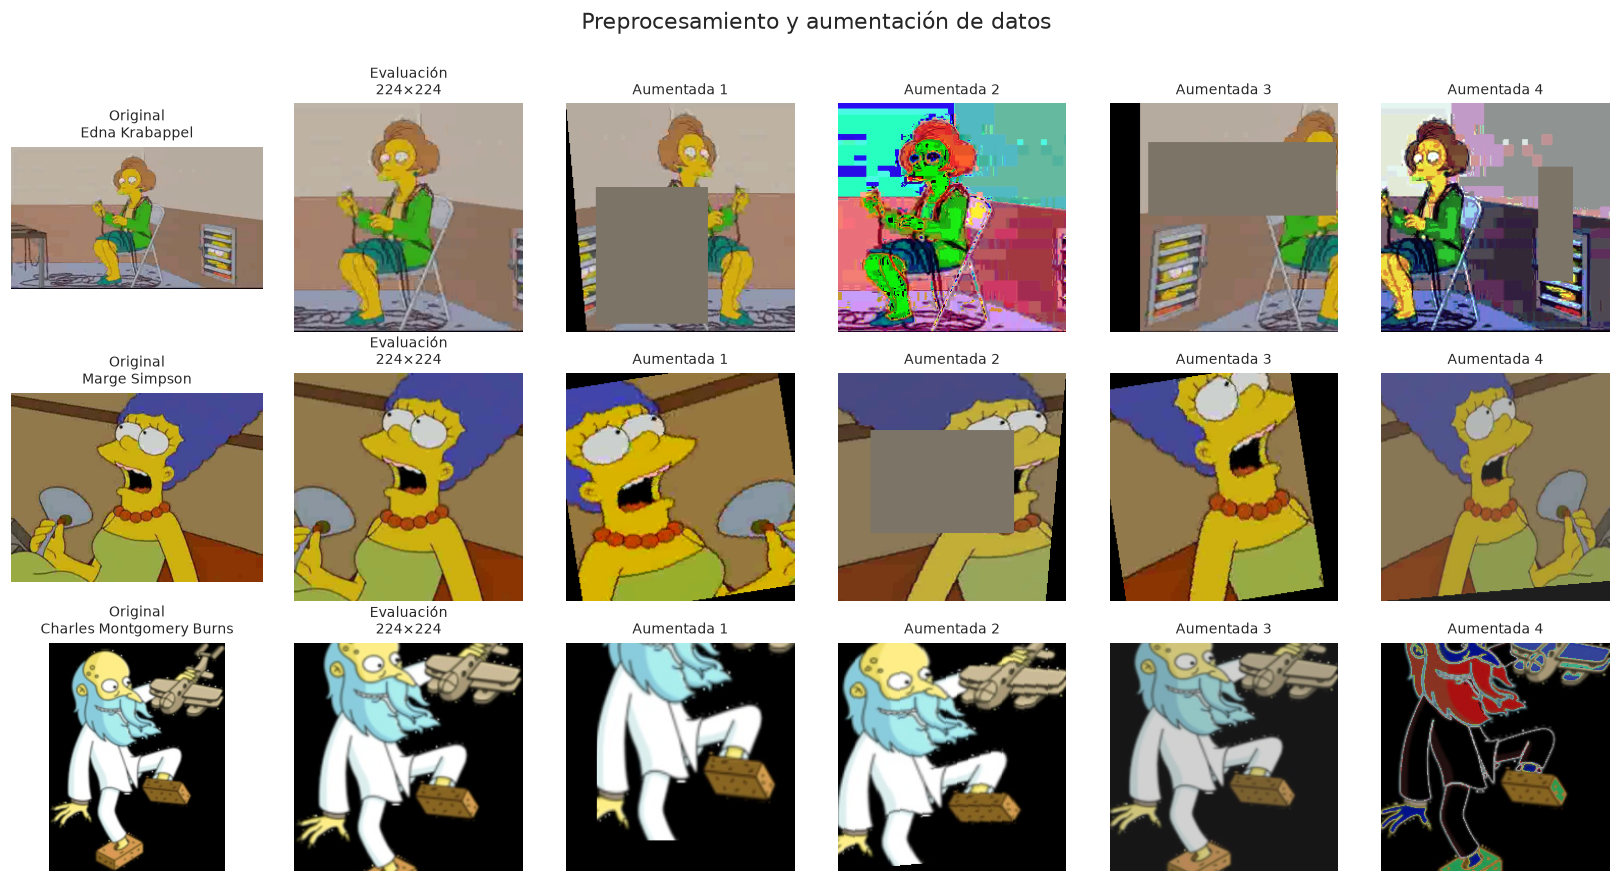

In [13]:
def a_imagen(tensor):
    return desnormalizar(tensor).permute(1, 2, 0).numpy()


ejemplos = train_df.sample(3, random_state=SEMILLA)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for fila_axes, (_, fila) in zip(axes, ejemplos.iterrows()):
    imagen = Image.open(fila["ruta"]).convert("RGB")
    fila_axes[0].imshow(imagen)
    fila_axes[0].set_title(f"Original\n{nombre_visible(fila['clase'])}", fontsize=9)
    fila_axes[1].imshow(a_imagen(transformacion_eval(imagen)))
    fila_axes[1].set_title(f"Evaluación\n{IMGSZ}×{IMGSZ}", fontsize=9)
    for j, ax in enumerate(fila_axes[2:], start=1):
        ax.imshow(a_imagen(aumentacion(imagen)))
        ax.set_title(f"Aumentada {j}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Preprocesamiento y aumentación de datos", y=1.0)
fig.tight_layout()
guardar_figura(fig, "05_aumentacion")
plt.show()

## 4. Arquitectura: ResNet-50 con transfer learning

**Por qué transfer learning.** Con unas 14.000 imágenes de entrenamiento, entrenar los 25 millones de parámetros de una ResNet-50 desde cero tiende al sobreajuste. Por eso se parte de los **pesos** de una ResNet-50 entrenada con ImageNet-1k (1,28 millones de fotos, 1.000 clases); no se usan sus imágenes. Las primeras capas ya detectan bordes, colores y texturas, que son universales y sirven también para dibujos animados; las intermedias, formas y patrones; las profundas, partes de objetos reales. Como las caricaturas difieren de las fotos, se ajustan **todas** las capas (*fine-tuning*). Se usan los pesos **V2** (80,9 % top-1 en ImageNet): misma arquitectura que los V1 (76,1 %), pero entrenados con una receta más moderna, por lo que son un mejor punto de partida. YOLO11m-cls también está preentrenado en ImageNet, así que ambos modelos parten de la misma base.

**Conexiones residuales.** Cada bloque aprende una corrección $F(x)$ que se suma a su entrada: $y = F(x) + x$. El atajo (*skip connection*) deja pasar el gradiente sin atenuarse, lo que permite entrenar redes de 50 o más capas sin la degradación que sufren las redes profundas "planas".

**Bloque bottleneck (1×1 → 3×3 → 1×1).** La primera convolución 1×1 reduce los canales (p. ej. de 256 a 64), la 3×3 trabaja sobre esa versión reducida y la última 1×1 los vuelve a expandir. Así se gana profundidad con mucho menos cómputo que con dos convoluciones 3×3 de ancho completo.

| Etapa | Contenido | Salida (entrada de 224×224) |
|---|---|---|
| `conv1` + `maxpool` | Convolución 7×7 con *stride* 2, *batch normalization*, ReLU y *max pooling* | 64 × 56 × 56 |
| `layer1` | 3 bloques bottleneck | 256 × 56 × 56 |
| `layer2` | 4 bloques bottleneck | 512 × 28 × 28 |
| `layer3` | 6 bloques bottleneck | 1.024 × 14 × 14 |
| `layer4` | 3 bloques bottleneck | 2.048 × 7 × 7 |
| `avgpool` | *Global average pooling*: un valor por canal | 2.048 |
| `fc` (cabeza nueva) | *Dropout* + capa lineal (→ *softmax* en inferencia) | 25 |

Son 16 bloques × 3 convoluciones + `conv1` + `fc` = **50 capas con pesos**.

**Por qué la variante 50.**

| Modelo | Bloque | Parámetros | GFLOPs* | Top-1 ImageNet |
|---|---|---|---|---|
| ResNet-18 | básico | 11,7 M | 3,6 | 69,8 % |
| ResNet-34 | básico | 21,8 M | 7,3 | 73,3 % |
| **ResNet-50** | **bottleneck** | **25,6 M** | **8,2** | **76,1 % (V1) / 80,9 % (V2)** |
| ResNet-101 | bottleneck | 44,5 M | 15,6 | 77,4 % / 81,9 % |
| ResNet-152 | bottleneck | 60,2 M | 23,0 | 78,3 % / 82,3 % |

\*GFLOPs = 2 × multiplicaciones-acumulaciones, la convención que usa Ultralytics para YOLO11 (torchvision publica la mitad: 4,1 para ResNet-50). La 50 es el punto de equilibrio de la familia: es la primera con bloques bottleneck y, con un cómputo parecido al de la 34, gana casi 3 puntos (V1); la 101 y la 152 duplican o triplican el costo para ganar entre 1,3 y 2,2 puntos (V1).

**Cabeza y fine-tuning en dos etapas.**

1. **Etapa 1** (`epocas_congeladas`, por defecto 3): el *backbone* queda congelado, incluidas sus estadísticas de *batch normalization*, y solo se entrena la cabeza nueva, que parte con pesos aleatorios. Así sus primeros gradientes, grandes y ruidosos, no dañan los pesos preentrenados.
2. **Etapa 2**: se descongela toda la red. El *backbone* usa un learning rate 10 veces menor que la cabeza (*learning rate discriminativo*): se adapta a los Simpson sin "olvidar" lo aprendido en ImageNet.

**Decisiones de entrenamiento**

- **Función de pérdida:** entropía cruzada con *label smoothing* 0,1: la clase correcta recibe una probabilidad objetivo de 0,904 y el resto se reparte entre las otras 24. Evita confianzas extremas y regulariza. Por eso la loss de entrenamiento no baja de ~0,62; las losses "de entrenamiento sin aumentación", de validación y de prueba se calculan **sin** *label smoothing*, para que sean comparables entre sí y con YOLO11.
- **AdamW** con *weight decay* desacoplado, **calentamiento** de 1 época y **decaimiento coseno** hasta `lr · lrf`.
- **Dropout 0,2, aumentación de datos, label smoothing y detención anticipada (paciencia 7):** mecanismos contra el sobreajuste.
- **Precisión mixta (AMP)** y formato `channels_last`: más velocidad y menos memoria en la GPU.
- **224×224 px:** la resolución de preentrenamiento, la misma que YOLO11.

In [14]:
def crear_modelo(n_clases, dropout, pesos=PESOS_PREENTRENADOS):
    modelo = resnet50(weights=pesos)
    modelo.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(modelo.fc.in_features, n_clases))
    return modelo


def contar_gflops(modelo, imgsz):
    # GFLOPs de una imagen = 2 × multiplicaciones-acumulaciones (misma convención que Ultralytics)
    m = deepcopy(modelo).float().cpu().eval()
    with FlopCounterMode(display=False) as contador, torch.no_grad():
        m(torch.zeros(1, 3, imgsz, imgsz))
    return contador.get_total_flops() / 1e9


modelo_base = crear_modelo(len(CLASES), HIPERPARAMETROS["dropout"])
n_parametros = sum(p.numel() for p in modelo_base.parameters())
print(f"ResNet-50 (pesos {PESOS_PREENTRENADOS.name}): {n_parametros / 1e6:.2f} M parámetros, "
      f"{contar_gflops(modelo_base, IMGSZ):.2f} GFLOPs a {IMGSZ}×{IMGSZ}")
print(f"\nCabeza nueva (reemplaza la capa de 1.000 clases de ImageNet por una de {len(CLASES)}):")
print(modelo_base.fc)

ResNet-50 (pesos IMAGENET1K_V2): 23.56 M parámetros, 8.17 GFLOPs a 224×224

Cabeza nueva (reemplaza la capa de 1.000 clases de ImageNet por una de 25):
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=2048, out_features=25, bias=True)
)


In [15]:
# Parámetros por etapa
resumen_capas = pd.DataFrame(
    [
        {
            "etapa": nombre,
            "bloques": len(m) if nombre.startswith("layer") else "—",
            "parámetros": sum(p.numel() for p in m.parameters()),
        }
        for nombre, m in modelo_base.named_children()
        if sum(p.numel() for p in m.parameters()) > 0
    ]
)
resumen_capas["% del total"] = (100 * resumen_capas["parámetros"] / n_parametros).round(1)
display(resumen_capas)

,etapa,bloques,parámetros,% del total
0,conv1,—,9408,0.0
1,bn1,—,128,0.0
2,layer1,3,215808,0.9
3,layer2,4,1219584,5.2
4,layer3,6,7098368,30.1
5,layer4,3,14964736,63.5
6,fc,—,51225,0.2


## 5. Entrenamiento

Antes de entrenar se guardan en la carpeta de la prueba: la configuración completa, la división, el orden de clases y una copia del notebook. Cada época agrega una línea a `entrenamiento.log` y a `historial.csv`, así que si el entrenamiento se interrumpe no se pierde lo registrado. Si se detiene a mano (botón *Interrupt*), la celda termina con el mejor peso guardado hasta ese momento y las celdas siguientes lo evalúan.

**Métricas por época**

- *Loss* de entrenamiento con aumentación y *label smoothing*: la que optimiza el modelo.
- *Loss* y *accuracy* de una muestra fija y estratificada de *train* **sin aumentación** (1.500 imágenes): comparables con validación, igual que en `yolo11.ipynb`.
- *Loss*, *accuracy* top-1 y top-5 de validación; learning rate de cada grupo y etapa.

**Mejor peso.** `weights/best.pt` es el modelo completo de la época con mayor *accuracy* top-1 de validación (en empate, la de menor *loss*); `weights/last.pt`, el de la última época. YOLO11 elige por el promedio de top-1 y top-5, pero aquí top-5 llega a casi 100 % desde las primeras épocas y no discrimina.

In [16]:
def semilla_worker(_):
    # Cada proceso del DataLoader deriva sus semillas de la del lote (reproducible)
    semilla = torch.initial_seed() % 2**32
    np.random.seed(semilla)
    random.seed(semilla)


def crear_cargador(dataset, barajar, lote, generador=None, persistente=False):
    workers = HIPERPARAMETROS["workers"]
    return DataLoader(
        dataset,
        batch_size=lote,
        shuffle=barajar,
        num_workers=workers,
        pin_memory=True,
        persistent_workers=persistente and workers > 0,
        multiprocessing_context=CONTEXTO_WORKERS,
        worker_init_fn=semilla_worker,
        generator=generador,
    )


def congelar_backbone(modelo, congelar):
    # Etapa 1: solo la cabeza (fc) es entrenable
    for nombre, parametro in modelo.named_parameters():
        parametro.requires_grad = not congelar or nombre.startswith("fc.")


def modo_entrenamiento(modelo, backbone_congelado):
    modelo.train()
    if backbone_congelado:
        # Las estadísticas de batch normalization del backbone se mantienen como en ImageNet
        for m in modelo.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()


def crear_optimizador(modelo, h):
    grupos = [
        {"params": [p for n, p in modelo.named_parameters() if not n.startswith("fc.")], "lr": h["lr_backbone"]},
        {"params": [p for n, p in modelo.named_parameters() if n.startswith("fc.")], "lr": h["lr_cabeza"]},
    ]
    if h["optimizer"] == "AdamW":
        return torch.optim.AdamW(grupos, weight_decay=h["weight_decay"])
    if h["optimizer"] == "SGD":
        return torch.optim.SGD(grupos, momentum=0.9, nesterov=True, weight_decay=h["weight_decay"])
    raise ValueError(f"Optimizador no soportado: {h['optimizer']}")


def crear_planificador(optimizador, h, iteraciones_por_epoca):
    # Calentamiento lineal y luego decaimiento coseno hasta lr * lrf, actualizado en cada iteración
    total = h["epochs"] * iteraciones_por_epoca
    calentamiento = max(1, int(h["warmup_epochs"] * iteraciones_por_epoca))

    def factor(i):
        if i < calentamiento:
            return (i + 1) / calentamiento
        progreso = min(1.0, (i - calentamiento) / max(1, total - calentamiento))
        return h["lrf"] + (1 - h["lrf"]) * 0.5 * (1 + np.cos(np.pi * progreso))

    return torch.optim.lr_scheduler.LambdaLR(optimizador, factor)


def pesos_por_clase(df, potencia):
    # Peso de cada clase ∝ (1 / frecuencia) ** potencia, normalizado para que el promedio sea 1
    frecuencia = df["clase"].value_counts().reindex(CLASES).to_numpy(dtype=float)
    pesos = (1.0 / frecuencia) ** potencia
    return torch.tensor(pesos / pesos.mean(), dtype=torch.float32)


def a_gpu(x, y):
    return x.to(DEVICE, non_blocking=True, memory_format=torch.channels_last), y.to(DEVICE, non_blocking=True)


def entrenar_epoca(modelo, cargador, criterio, optimizador, planificador, escalador, amp, backbone_congelado):
    modo_entrenamiento(modelo, backbone_congelado)
    perdida, n = 0.0, 0
    for x, y in cargador:
        x, y = a_gpu(x, y)
        optimizador.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
            loss = criterio(modelo(x), y)
        escalador.scale(loss).backward()
        escalador.step(optimizador)
        escalador.update()
        planificador.step()
        perdida += loss.item() * len(y)
        n += len(y)
    return perdida / n


@torch.no_grad()
def evaluar(modelo, cargador, amp=True):
    # Loss (entropía cruzada sin label smoothing), accuracy top-1 y top-5, y las probabilidades de cada imagen
    modelo.eval()
    perdida, probabilidades, etiquetas = 0.0, [], []
    for x, y in cargador:
        x, y = a_gpu(x, y)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
            logits = modelo(x).float()
        perdida += F.cross_entropy(logits, y, reduction="sum").item()
        probabilidades.append(logits.softmax(1).cpu())
        etiquetas.append(y.cpu())
    P, y = torch.cat(probabilidades), torch.cat(etiquetas)
    top5 = P.topk(min(5, P.shape[1]), dim=1).indices
    return {
        "loss": perdida / len(y),
        "top1": (P.argmax(1) == y).float().mean().item(),
        "top5": (top5 == y[:, None]).any(1).float().mean().item(),
        "probabilidades": P.numpy(),
        "etiquetas": y.numpy(),
    }


def ruta_notebook():
    ruta = globals().get("__vsc_ipynb_file__")  # VS Code define esta variable con la ruta del notebook
    return Path(ruta) if ruta else BASE_DIR / "resnet50.ipynb"

In [17]:
if TEST_A_EVALUAR is None:
    h = HIPERPARAMETROS
    # Semillas de nuevo: el resultado no depende de lo que se haya ejecutado antes en el notebook
    random.seed(SEMILLA)
    np.random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)

    # 1) Registro previo al entrenamiento
    division_csv = division.assign(ruta=division["ruta"].map(lambda r: r.relative_to(BASE_DIR).as_posix()))
    division_csv[["ruta", "archivo", "clase", "subconjunto", "md5"]].to_csv(TEST_DIR / "division.csv", index=False)
    guardar_json(CLASES, TEST_DIR / "clases.json")
    if ruta_notebook().exists():
        shutil.copy2(ruta_notebook(), TEST_DIR / "resnet50_copia.ipynb")

    configuracion = {
        "prueba": NOMBRE_TEST,
        "notebook": "resnet50.ipynb",
        "modelo_base": MODELO_BASE,
        "nombre_modelo": NOMBRE_MODELO,
        "pesos_preentrenados": PESOS_PREENTRENADOS.name,
        "datos": {
            "dataset_dividido": SPLIT_DIR.relative_to(BASE_DIR).as_posix(),
            "clases": len(CLASES),
            "imagenes": {s: int((division["subconjunto"] == s).sum()) for s in ["train", "val", "test"]},
        },
        "preprocesamiento": PREPROCESAMIENTO,
        "hiperparametros": h,
        "evaluacion": EVALUACION,
        "entorno": ENTORNO,
        "inicio": datetime.now().isoformat(timespec="seconds"),
    }
    guardar_json(configuracion, TEST_DIR / "configuracion.json")
    WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

    # 2) Datos: train con aumentación; muestra fija de train y validación sin aumentación
    n_muestra = min(EVALUACION["muestra_train_por_epoca"], len(train_df) - len(CLASES))
    muestra, _ = train_test_split(train_df, train_size=n_muestra, stratify=train_df["clase"], random_state=SEMILLA)
    cargador_train = crear_cargador(
        crear_dataset(train_df, aumentacion), True, h["batch"], torch.Generator().manual_seed(SEMILLA), persistente=True
    )
    cargador_muestra = crear_cargador(crear_dataset(muestra, transformacion_eval), False, EVALUACION["lote_inferencia"])
    cargador_val = crear_cargador(crear_dataset(val_df, transformacion_eval), False, EVALUACION["lote_inferencia"])

    # 3) Modelo, función de pérdida, optimizador y planificador del learning rate
    modelo = crear_modelo(len(CLASES), h["dropout"]).to(DEVICE, memory_format=torch.channels_last)
    pesos = pesos_por_clase(train_df, h["peso_clases"]).to(DEVICE) if h["peso_clases"] else None
    criterio = nn.CrossEntropyLoss(weight=pesos, label_smoothing=h["label_smoothing"])
    optimizador = crear_optimizador(modelo, h)
    planificador = crear_planificador(optimizador, h, len(cargador_train))
    escalador = torch.amp.GradScaler("cuda", enabled=h["amp"])

    # 4) Entrenamiento con detención anticipada
    filas, mejor, mejor_epoca, sin_mejora = [], None, None, 0
    inicio = time.time()
    try:
        for epoca in range(1, h["epochs"] + 1):
            congelado = epoca <= h["epocas_congeladas"]
            congelar_backbone(modelo, congelado)
            t0 = time.time()
            loss_train = entrenar_epoca(modelo, cargador_train, criterio, optimizador, planificador, escalador, h["amp"], congelado)
            ev_muestra = evaluar(modelo, cargador_muestra, h["amp"])
            ev_val = evaluar(modelo, cargador_val, h["amp"])
            fila = {
                "epoch": epoca,
                "etapa": "solo cabeza" if congelado else "red completa",
                "train/loss": loss_train,
                "train/loss_sin_aumentacion": ev_muestra["loss"],
                "train/accuracy_top1": ev_muestra["top1"],
                "val/loss": ev_val["loss"],
                "metrics/accuracy_top1": ev_val["top1"],
                "metrics/accuracy_top5": ev_val["top5"],
                "lr/backbone": optimizador.param_groups[0]["lr"],
                "lr/cabeza": optimizador.param_groups[1]["lr"],
                "tiempo_s": round(time.time() - t0, 1),
            }
            filas.append(fila)
            pd.DataFrame(filas).to_csv(TEST_DIR / "historial.csv", index=False)

            torch.save(modelo, WEIGHTS_DIR / "last.pt")
            clave = (ev_val["top1"], -ev_val["loss"])
            mejoro = mejor is None or clave > mejor
            if mejoro:
                mejor, mejor_epoca, sin_mejora = clave, epoca, 0
                torch.save(modelo, WEIGHTS_DIR / "best.pt")
            else:
                sin_mejora += 1

            linea = (
                f"Época {epoca:>2}/{h['epochs']} [{fila['etapa']}] loss train {loss_train:.4f} | "
                f"acc train {ev_muestra['top1']:.4f} | loss val {ev_val['loss']:.4f} | acc val {ev_val['top1']:.4f} | "
                f"top-5 val {ev_val['top5']:.4f} | {fila['tiempo_s']:.0f} s{' *' if mejoro else ''}"
            )
            print(linea)
            with open(TEST_DIR / "entrenamiento.log", "a", encoding="utf-8") as registro:
                registro.write(f"{datetime.now().isoformat(timespec='seconds')} {linea}\n")
            if sin_mejora >= h["patience"]:
                print(f"Detención anticipada: {h['patience']} épocas sin mejorar la accuracy de validación.")
                break
    except KeyboardInterrupt:
        print("Entrenamiento detenido a mano: se conserva el mejor peso guardado hasta ahora.")
    finally:
        duracion_min = (time.time() - inicio) / 60
        del cargador_train  # cierra los procesos persistentes del DataLoader

    assert filas, "El entrenamiento se detuvo antes de completar la primera época: no hay peso que evaluar."

    # 5) Historial y cierre de la configuración
    historial = pd.DataFrame(filas)
    configuracion.update(
        {
            "fin": datetime.now().isoformat(timespec="seconds"),
            "duracion_min": round(duracion_min, 1),
            "epocas_ejecutadas": int(historial["epoch"].max()),
            "mejor_epoca_val_top1": int(mejor_epoca),
        }
    )
    guardar_json(configuracion, TEST_DIR / "configuracion.json")
    print(f"Entrenamiento terminado en {duracion_min:.1f} min ({configuracion['epocas_ejecutadas']} épocas; "
          f"mejor época: {mejor_epoca}). '*' = se guardó como best.pt")
else:
    historial = pd.read_csv(TEST_DIR / "historial.csv")
    configuracion = json.loads((TEST_DIR / "configuracion.json").read_text(encoding="utf-8"))
    print(f"Se reevalúa {NOMBRE_TEST} (entrenada el {configuracion['inicio']}); no se entrena de nuevo.")

display(historial.tail())

Época  1/50 [solo cabeza] loss train 2.7868 | acc train 0.5320 | loss val 2.1734 | acc val 0.5059 | top-5 val 0.8088 | 23 s *
Época  2/50 [solo cabeza] loss train 2.1113 | acc train 0.6680 | loss val 1.6014 | acc val 0.6443 | top-5 val 0.8871 | 22 s *
Época  3/50 [solo cabeza] loss train 1.8525 | acc train 0.7400 | loss val 1.3605 | acc val 0.7163 | top-5 val 0.9214 | 22 s *
Época  4/50 [red completa] loss train 1.1814 | acc train 0.9753 | loss val 0.2517 | acc val 0.9680 | top-5 val 0.9937 | 47 s *
Época  5/50 [red completa] loss train 0.8826 | acc train 0.9927 | loss val 0.1789 | acc val 0.9825 | top-5 val 0.9947 | 47 s *
Época  6/50 [red completa] loss train 0.8101 | acc train 0.9940 | loss val 0.1633 | acc val 0.9848 | top-5 val 0.9964 | 47 s *
Época  7/50 [red completa] loss train 0.7700 | acc train 0.9967 | loss val 0.1380 | acc val 0.9861 | top-5 val 0.9954 | 47 s *
Época  8/50 [red completa] loss train 0.7530 | acc train 0.9987 | loss val 0.1351 | acc val 0.9884 | top-5 val 0.9

,epoch,etapa,train/loss,train/loss_sin_aumentacion,train/accuracy_top1,val/loss,metrics/accuracy_top1,metrics/accuracy_top5,lr/backbone,lr/cabeza,tiempo_s
45,46,red completa,0.651277,0.098531,0.999333,0.129705,0.993065,0.998019,0.000003,0.000026,47.1
46,47,red completa,0.651300,0.096279,0.999333,0.126966,0.993395,0.998019,0.000002,0.000019,46.8
47,48,red completa,0.648825,0.099395,0.999333,0.130713,0.993065,0.998019,0.000001,0.000014,46.7
48,49,red completa,0.650104,0.097027,0.999333,0.127677,0.993065,0.998019,0.000001,0.000011,47.3
49,50,red completa,0.652373,0.097404,0.999333,0.128042,0.993395,0.998019,0.000001,0.000010,47.1


## 6. Curvas de aprendizaje

- **Loss:** la de entrenamiento con aumentación y *label smoothing* (la que optimiza el modelo; no baja de ~0,62), la de entrenamiento sin aumentación (muestra fija) y la de validación. Las dos últimas son directamente comparables.
- **Accuracy:** entrenamiento (muestra fija, sin aumentación) contra validación (top-1 y top-5).
- La línea morada marca el paso de la etapa 1 (solo cabeza) a la etapa 2 (red completa).

Una brecha creciente entre entrenamiento y validación indica **sobreajuste**; valores bajos en ambas indican **subajuste**.

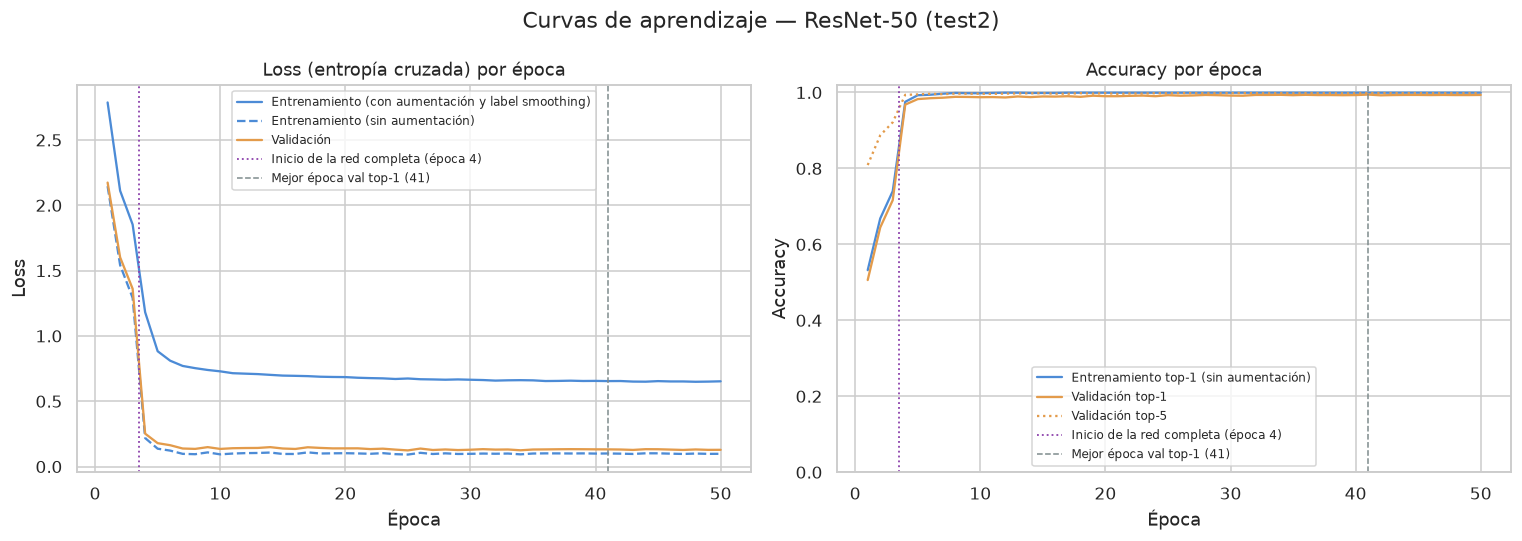

Última época: accuracy train 0.999 | val 0.993 | brecha +0.006


In [18]:
# Si la prueba se cortó sin cerrar configuracion.json, la mejor época se recupera del historial
mejor_epoca = int(
    configuracion.get("mejor_epoca_val_top1")
    or historial.sort_values(["metrics/accuracy_top1", "val/loss"], ascending=[False, True]).iloc[0]["epoch"]
)
inicio_etapa2 = configuracion["hiperparametros"]["epocas_congeladas"] + 1

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))
ax_loss.plot(historial["epoch"], historial["train/loss"], label="Entrenamiento (con aumentación y label smoothing)", color="#4C8BD6")
ax_loss.plot(historial["epoch"], historial["train/loss_sin_aumentacion"], label="Entrenamiento (sin aumentación)", color="#4C8BD6", ls="--")
ax_loss.plot(historial["epoch"], historial["val/loss"], label="Validación", color="#E39B4B")
ax_loss.set(title="Loss (entropía cruzada) por época", xlabel="Época", ylabel="Loss")

ax_acc.plot(historial["epoch"], historial["train/accuracy_top1"], label="Entrenamiento top-1 (sin aumentación)", color="#4C8BD6")
ax_acc.plot(historial["epoch"], historial["metrics/accuracy_top1"], label="Validación top-1", color="#E39B4B")
ax_acc.plot(historial["epoch"], historial["metrics/accuracy_top5"], label="Validación top-5", color="#E39B4B", ls=":")
ax_acc.set(title="Accuracy por época", xlabel="Época", ylabel="Accuracy", ylim=(0, 1.02))

for ax in (ax_loss, ax_acc):
    if 1 < inicio_etapa2 <= historial["epoch"].max():
        ax.axvline(inicio_etapa2 - 0.5, color="#8E44AD", ls=":", lw=1.2, label=f"Inicio de la red completa (época {inicio_etapa2})")
    ax.axvline(mejor_epoca, color="#7F8C8D", ls="--", lw=1, label=f"Mejor época val top-1 ({mejor_epoca})")
    ax.legend(fontsize=8)
fig.suptitle(f"Curvas de aprendizaje — ResNet-50 ({NOMBRE_TEST})")
fig.tight_layout()
guardar_figura(fig, "06_curvas_aprendizaje")
plt.show()

final = historial.iloc[-1]
brecha = final["train/accuracy_top1"] - final["metrics/accuracy_top1"]
print(f"Última época: accuracy train {final['train/accuracy_top1']:.3f} | val {final['metrics/accuracy_top1']:.3f} | brecha {brecha:+.3f}")

## 7. Evaluación en el conjunto de prueba

Se evalúa el mejor peso (`best.pt`) sobre el conjunto de prueba, que el modelo no vio durante el entrenamiento ni se usó para elegir el peso. La división y el preprocesamiento se leen desde la carpeta de la prueba, así que la evaluación es la misma aunque se reevalúe después. Son las mismas 3.028 imágenes de prueba que usa YOLO11.

- **Accuracy:** proporción de imágenes bien clasificadas.
- **Precision:** de las veces que el modelo predijo un personaje, cuántas acertó.
- **Recall (sensibilidad):** de las imágenes de un personaje, cuántas reconoció.
- **F1-score:** media armónica de *precision* y *recall*.
- Promedio **macro** (todas las clases pesan igual, sensible a las clases pequeñas) y **ponderado** (según el número de imágenes de cada clase).

In [19]:
mejor_modelo = torch.load(TEST_DIR / "weights" / "best.pt", map_location=DEVICE, weights_only=False).eval()
NOMBRES = json.loads((TEST_DIR / "clases.json").read_text(encoding="utf-8"))
division_prueba = pd.read_csv(TEST_DIR / "division.csv")
test_eval = division_prueba[division_prueba["subconjunto"] == "test"].reset_index(drop=True)
rutas_test = [BASE_DIR / r for r in test_eval["ruta"]]

cargador_test = crear_cargador(
    ImagenesSimpsons(rutas_test, [NOMBRES.index(c) for c in test_eval["clase"]],
                     crear_transformacion_eval(configuracion["preprocesamiento"])),
    False,
    EVALUACION["lote_inferencia"],
)
ev_test = evaluar(mejor_modelo, cargador_test, configuracion["hiperparametros"]["amp"])
P = ev_test["probabilidades"]
y_true = ev_test["etiquetas"]
y_pred = P.argmax(1)
confianza = P.max(1)
top5 = np.argsort(-P, axis=1)[:, :5]

prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
metricas_test = {
    "imagenes_test": int(len(y_true)),
    "accuracy": accuracy_score(y_true, y_pred),
    "accuracy_top5": float(np.mean([y in t for y, t in zip(y_true, top5)])),
    "precision_macro": prec_m,
    "recall_macro": rec_m,
    "f1_macro": f1_m,
    "precision_ponderada": prec_w,
    "recall_ponderado": rec_w,
    "f1_ponderado": f1_w,
}
metricas_test = {k: v if isinstance(v, int) else round(float(v), 4) for k, v in metricas_test.items()}
guardar_json(metricas_test, TEST_DIR / "metricas_test.json")
print(f"Loss de prueba (sin label smoothing): {ev_test['loss']:.4f}")
pd.Series(metricas_test, name=NOMBRE_TEST).to_frame()

Loss de prueba (sin label smoothing): 0.1297


,test2
imagenes_test,3028.0000
accuracy,0.9941
accuracy_top5,0.9977
precision_macro,0.9945
recall_macro,0.9923
f1_macro,0.9933
precision_ponderada,0.9941
recall_ponderado,0.9941
f1_ponderado,0.9941


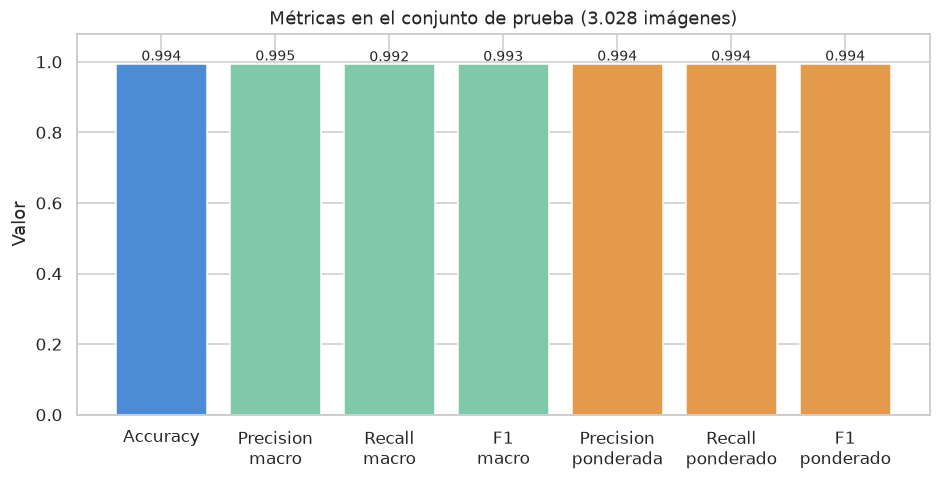

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.5))
claves = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "precision_ponderada", "recall_ponderado", "f1_ponderado"]
etiquetas = ["Accuracy", "Precision\nmacro", "Recall\nmacro", "F1\nmacro", "Precision\nponderada", "Recall\nponderado", "F1\nponderado"]
barras = ax.bar(etiquetas, [metricas_test[k] for k in claves], color=["#4C8BD6"] + ["#7FC8A9"] * 3 + ["#E39B4B"] * 3)
ax.bar_label(barras, fmt="%.3f", fontsize=9)
ax.set(ylim=(0, 1.08), ylabel="Valor", title=f"Métricas en el conjunto de prueba ({miles(metricas_test['imagenes_test'])} imágenes)")
guardar_figura(fig, "07_metricas_test")
plt.show()

### 7.1 Reporte por clase y matriz de confusión

In [21]:
reporte = pd.DataFrame(
    classification_report(
        y_true, y_pred, labels=range(len(NOMBRES)), target_names=NOMBRES, output_dict=True, zero_division=0
    )
).T
reporte.to_csv(TEST_DIR / "reporte_clasificacion.csv")
display(reporte.round(3))

,precision,recall,f1-score,support
abraham_grampa_simpson,1.000,1.000,1.000,137.000
apu_nahasapeemapetilon,1.000,1.000,1.000,93.000
barney_gumble,1.000,1.000,1.000,16.000
bart_simpson,0.985,0.995,0.990,201.000
charles_montgomery_burns,1.000,0.994,0.997,179.000
chief_wiggum,0.993,1.000,0.997,148.000
comic_book_guy,0.973,1.000,0.986,71.000
edna_krabappel,0.986,0.986,0.986,69.000
groundskeeper_willie,1.000,0.944,0.971,18.000
homer_simpson,0.991,0.994,0.993,337.000


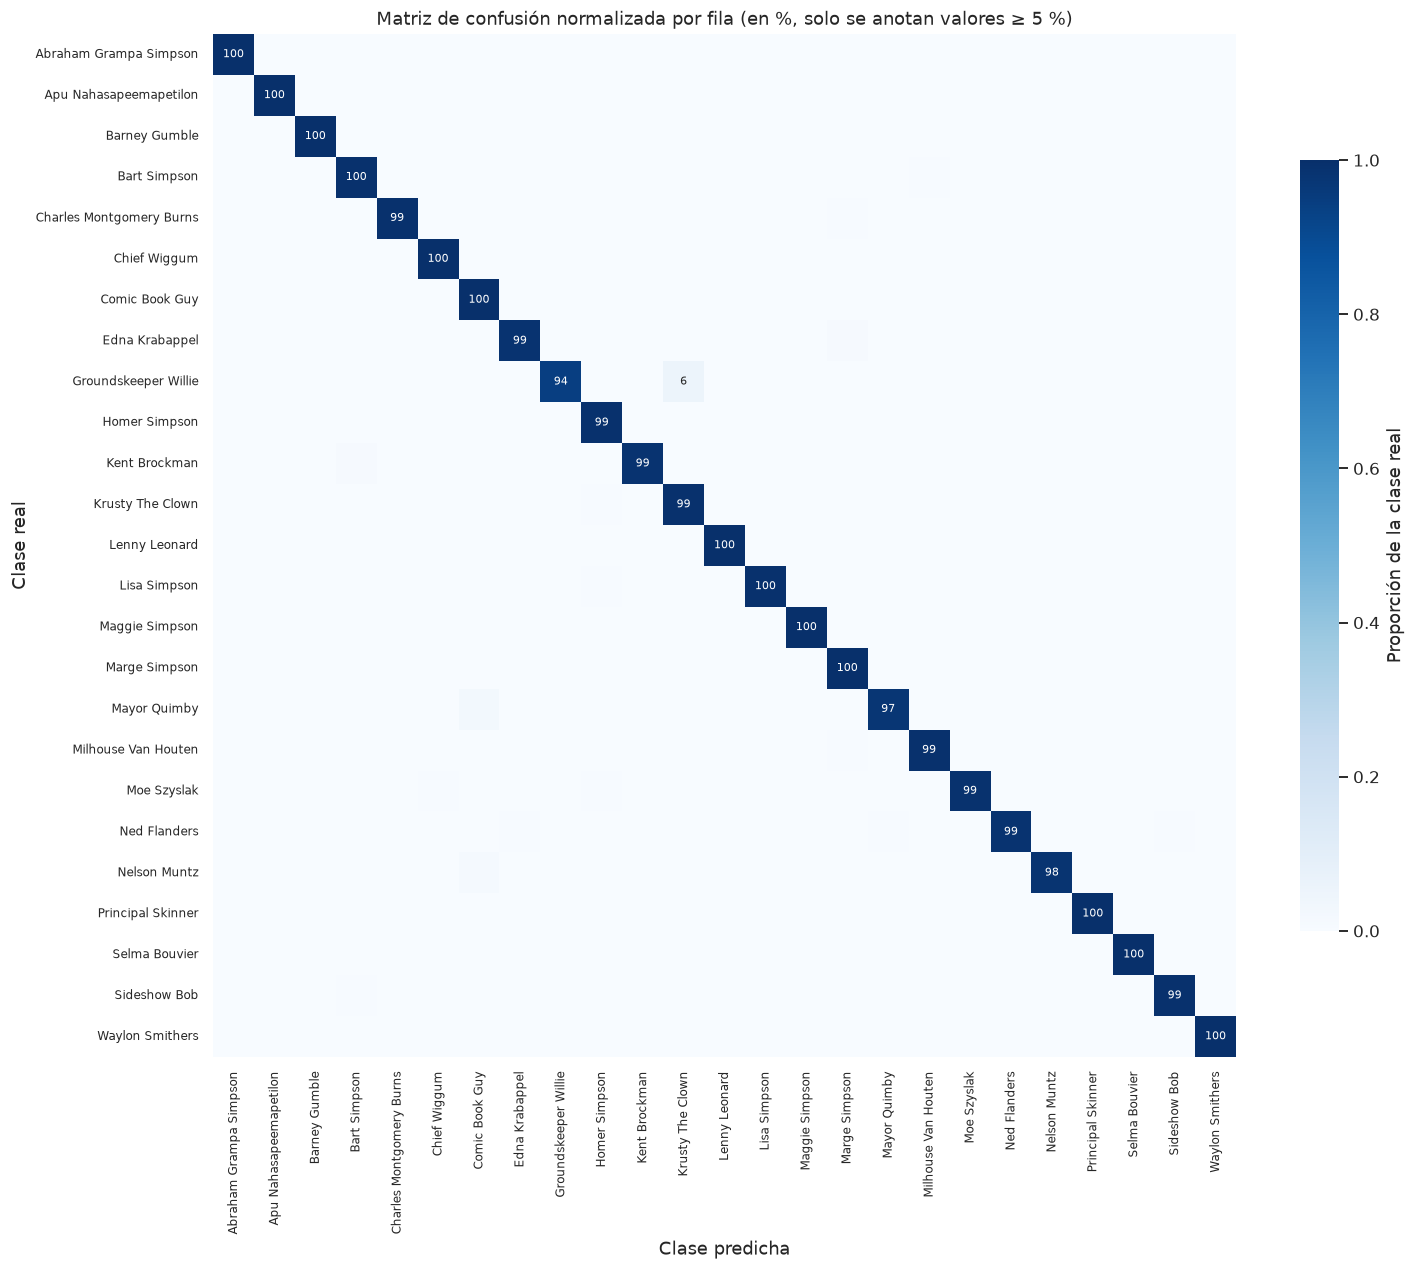

In [22]:
matriz = confusion_matrix(y_true, y_pred, labels=range(len(NOMBRES)))
pd.DataFrame(matriz, index=NOMBRES, columns=NOMBRES).to_csv(TEST_DIR / "matriz_confusion_test.csv")
matriz_norm = matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)

anotaciones = np.where(matriz_norm >= 0.05, np.vectorize(lambda v: f"{v:.0%}".replace("%", ""))(matriz_norm), "")
etiquetas_visibles = [nombre_visible(n) for n in NOMBRES]
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    matriz_norm, annot=anotaciones, fmt="", cmap="Blues", vmin=0, vmax=1, square=True,
    xticklabels=etiquetas_visibles, yticklabels=etiquetas_visibles, annot_kws={"fontsize": 7},
    cbar_kws={"label": "Proporción de la clase real", "shrink": 0.7}, ax=ax,
)
ax.set(xlabel="Clase predicha", ylabel="Clase real",
       title="Matriz de confusión normalizada por fila (en %, solo se anotan valores ≥ 5 %)")
ax.tick_params(labelsize=8)
guardar_figura(fig, "08_matriz_confusion")
plt.show()

### 7.2 Análisis de errores y sesgos

Se analiza si el desempeño depende del número de imágenes de entrenamiento de cada clase (sesgo hacia las clases mayoritarias), qué pares de personajes se confunden más y qué tan confiadas son las predicciones correctas e incorrectas. Esto último sirve para calibrar el umbral de confianza de la aplicación web.

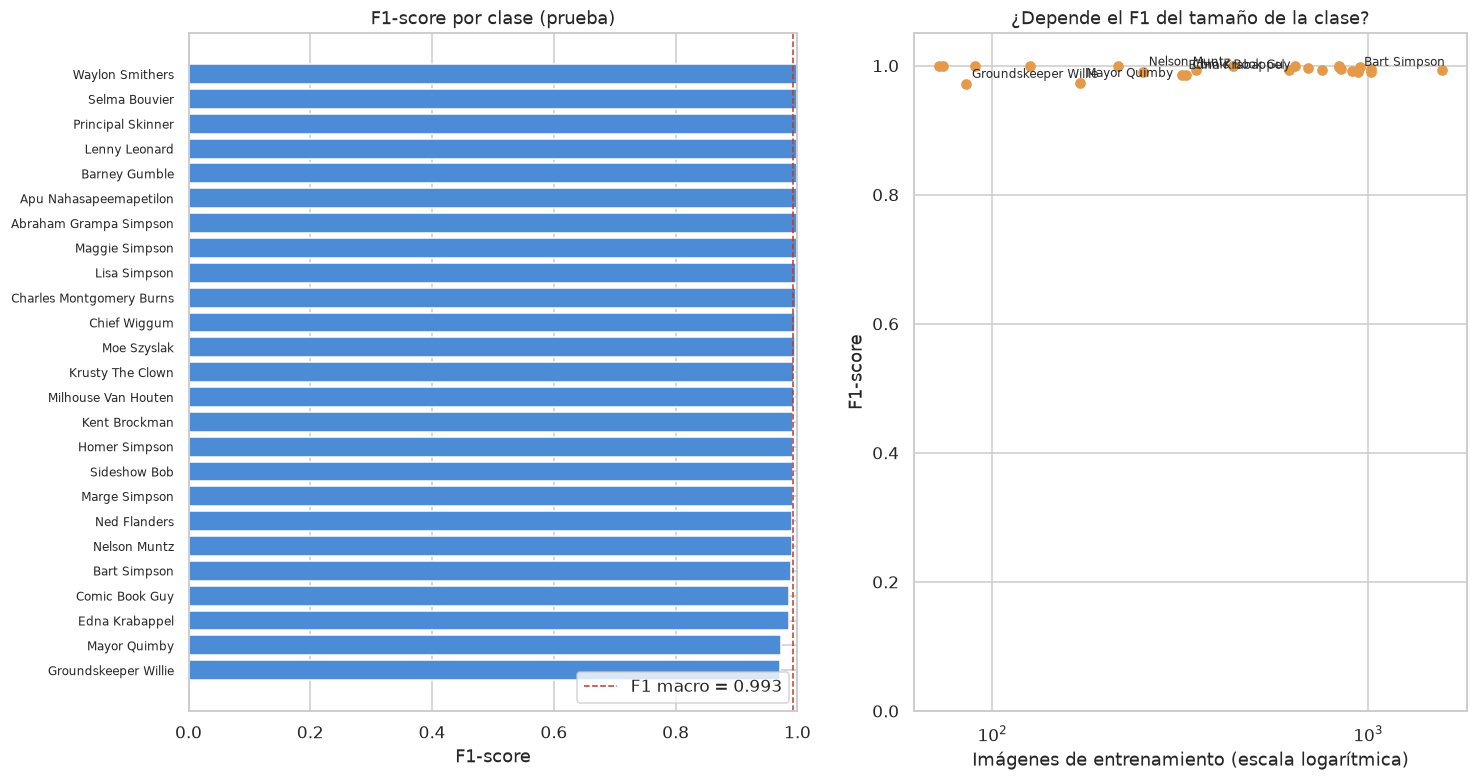

Correlación entre log(imágenes de train) y F1: +0.14


In [23]:
n_train = division_prueba[division_prueba["subconjunto"] == "train"]["clase"].value_counts()
por_clase = reporte.loc[NOMBRES, ["precision", "recall", "f1-score", "support"]].copy()
por_clase["imagenes_train"] = n_train.reindex(NOMBRES).values
por_clase = por_clase.sort_values("f1-score")

fig, (ax_bar, ax_disp) = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.1, 1]})
ax_bar.barh([nombre_visible(n) for n in por_clase.index], por_clase["f1-score"], color="#4C8BD6")
ax_bar.axvline(metricas_test["f1_macro"], color="#C0392B", ls="--", lw=1, label=f"F1 macro = {metricas_test['f1_macro']:.3f}")
ax_bar.set(xlim=(0, 1), xlabel="F1-score", title="F1-score por clase (prueba)")
ax_bar.tick_params(axis="y", labelsize=8)
ax_bar.legend(loc="lower right")

ax_disp.scatter(por_clase["imagenes_train"], por_clase["f1-score"], color="#E39B4B")
for nombre, fila in por_clase.head(6).iterrows():
    ax_disp.annotate(nombre_visible(nombre), (fila["imagenes_train"], fila["f1-score"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax_disp.set_xscale("log")
ax_disp.set(xlabel="Imágenes de entrenamiento (escala logarítmica)", ylabel="F1-score", ylim=(0, 1.05),
            title="¿Depende el F1 del tamaño de la clase?")
guardar_figura(fig, "09_f1_por_clase")
plt.show()

correlacion = np.corrcoef(np.log(por_clase["imagenes_train"]), por_clase["f1-score"])[0, 1]
print(f"Correlación entre log(imágenes de train) y F1: {correlacion:+.2f}")

In [24]:
pares = [
    {"real": NOMBRES[i], "predicha": NOMBRES[j], "errores": int(matriz[i, j]), "porcentaje_de_la_clase": matriz_norm[i, j]}
    for i in range(len(NOMBRES))
    for j in range(len(NOMBRES))
    if i != j and matriz[i, j] > 0
]
confusiones = pd.DataFrame(pares, columns=["real", "predicha", "errores", "porcentaje_de_la_clase"])
confusiones = confusiones.sort_values("errores", ascending=False).reset_index(drop=True)
confusiones.to_csv(TEST_DIR / "confusiones_frecuentes.csv", index=False)
print(f"Errores totales: {int((y_true != y_pred).sum())} de {len(y_true)}")
display(confusiones.head(10).style.format({"porcentaje_de_la_clase": "{:.1%}"}))

Errores totales: 18 de 3028


,real,predicha,errores,porcentaje_de_la_clase
0,bart_simpson,milhouse_van_houten,1,0.5%
1,charles_montgomery_burns,marge_simpson,1,0.6%
2,edna_krabappel,marge_simpson,1,1.4%
3,groundskeeper_willie,krusty_the_clown,1,5.6%
4,homer_simpson,bart_simpson,1,0.3%
5,homer_simpson,ned_flanders,1,0.3%
6,kent_brockman,bart_simpson,1,1.3%
7,krusty_the_clown,homer_simpson,1,0.6%
8,lisa_simpson,homer_simpson,1,0.5%
9,mayor_quimby,comic_book_guy,1,2.7%


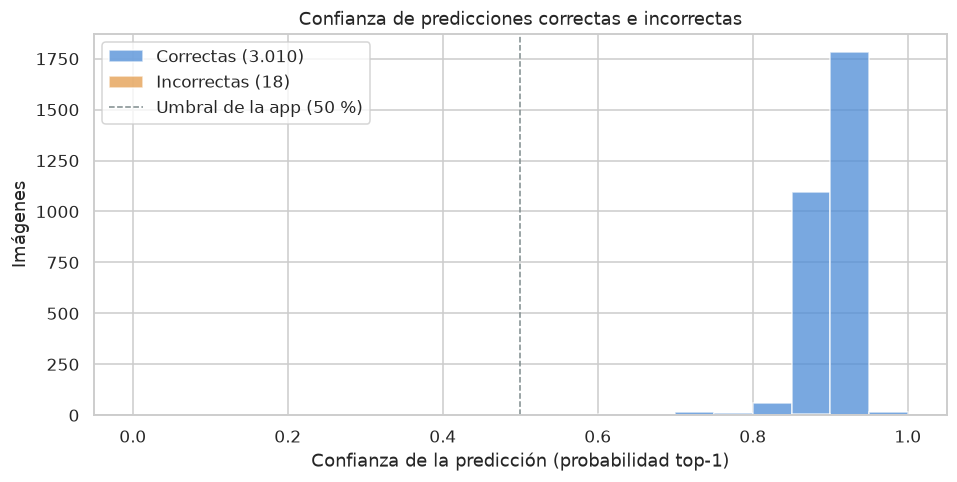

Confianza ≥ 50%: cubre 99.5% de las imágenes con accuracy 0.996
Confianza ≥ 70%: cubre 98.7% de las imágenes con accuracy 0.997
Confianza ≥ 90%: cubre 59.5% de las imágenes con accuracy 0.998


In [25]:
acierto = y_true == y_pred
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(0, 1, 21)
ax.hist(confianza[acierto], bins=bins, alpha=0.75, label=f"Correctas ({miles(acierto.sum())})", color="#4C8BD6")
ax.hist(confianza[~acierto], bins=bins, alpha=0.75, label=f"Incorrectas ({miles((~acierto).sum())})", color="#E39B4B")
ax.axvline(0.5, color="#7F8C8D", ls="--", lw=1, label="Umbral de la app (50 %)")
ax.set(xlabel="Confianza de la predicción (probabilidad top-1)", ylabel="Imágenes", title="Confianza de predicciones correctas e incorrectas")
ax.legend()
guardar_figura(fig, "10_confianza")
plt.show()

for u in (0.5, 0.7, 0.9):
    sobre = confianza >= u
    if sobre.any():
        print(f"Confianza ≥ {u:.0%}: cubre {sobre.mean():.1%} de las imágenes con accuracy {acierto[sobre].mean():.3f}")
    else:
        print(f"Confianza ≥ {u:.0%}: ninguna predicción alcanza este nivel")

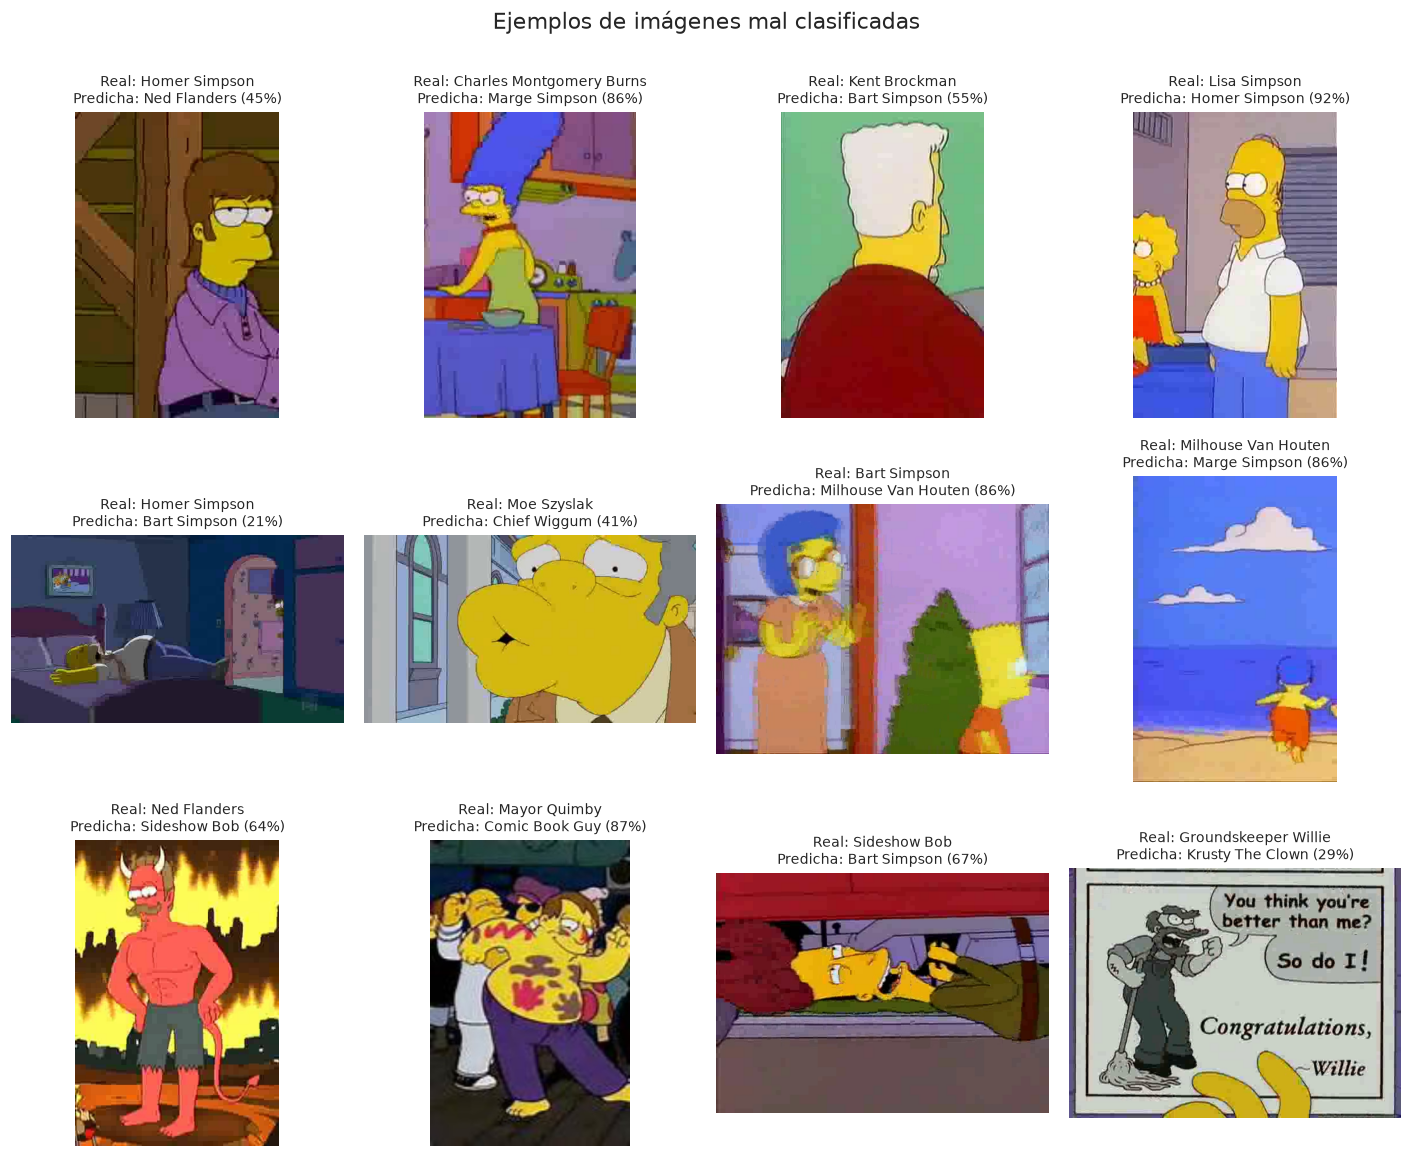

In [26]:
errores = np.flatnonzero(~acierto)
seleccion = np.random.default_rng(SEMILLA).choice(errores, size=min(12, len(errores)), replace=False) if len(errores) else []
if len(seleccion):
    fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
    for ax in axes.flat:
        ax.axis("off")
    for ax, k in zip(axes.flat, seleccion):
        ax.imshow(Image.open(rutas_test[k]).convert("RGB"))
        ax.set_title(f"Real: {nombre_visible(NOMBRES[y_true[k]])}\nPredicha: {nombre_visible(NOMBRES[y_pred[k]])} ({confianza[k]:.0%})", fontsize=9)
    fig.suptitle("Ejemplos de imágenes mal clasificadas", y=1.0)
    fig.tight_layout()
    guardar_figura(fig, "11_errores")
    plt.show()

### 7.3 Capacidad de generalización

In [27]:
mejor_val = historial.loc[historial["epoch"] == mejor_epoca].iloc[0]
generalizacion = pd.DataFrame(
    {
        "accuracy top-1": {
            "Entrenamiento (muestra, sin aumentación)": mejor_val["train/accuracy_top1"],
            "Validación": mejor_val["metrics/accuracy_top1"],
            "Prueba": metricas_test["accuracy"],
        }
    }
)
display(generalizacion.round(4))

acc_train = mejor_val["train/accuracy_top1"]
brecha_val = acc_train - mejor_val["metrics/accuracy_top1"]
brecha_test = mejor_val["metrics/accuracy_top1"] - metricas_test["accuracy"]
print(f"Brecha entrenamiento − validación: {brecha_val:+.3f}")
print(f"Brecha validación − prueba:        {brecha_test:+.3f}")
if brecha_val > 0.05:
    print("→ Señal de sobreajuste: el modelo rinde notoriamente mejor en entrenamiento que en validación.")
elif acc_train < 0.80:
    print("→ Señal de subajuste: el modelo no alcanza un buen desempeño ni siquiera en entrenamiento.")
else:
    print("→ Sin señales fuertes de sobreajuste ni subajuste según la brecha de accuracy.")

,accuracy top-1
"Entrenamiento (muestra, sin aumentación)",0.9993
Validación,0.9944
Prueba,0.9941


Brecha entrenamiento − validación: +0.005
Brecha validación − prueba:        +0.000
→ Sin señales fuertes de sobreajuste ni subajuste según la brecha de accuracy.


> **Análisis crítico (completar tras ejecutar):** interpretar las curvas (¿qué cambia al pasar a la red completa?, ¿en qué época se estabiliza la validación?, ¿crece la brecha?), las clases con menor F1 y su relación con el número de imágenes, los pares de personajes más confundidos (¿se parecen visualmente?, ¿son los mismos que confunde YOLO11?) y la confianza de los errores. Indicar posibles sesgos, por ejemplo hacia los personajes con más imágenes.

## 8. Costo computacional

Datos para justificar el modelo final según la relación entre precisión, costo y factibilidad de despliegue. Los GFLOPs usan la misma convención que Ultralytics (2 × multiplicaciones-acumulaciones), así que se pueden comparar directamente con los de YOLO11. La latencia se mide con una imagen a la vez, que es el caso de la aplicación web.

In [28]:
def medir_latencia(modelo, dispositivo, repeticiones, imgsz):
    m = deepcopy(modelo).float().to(dispositivo).eval()
    x = torch.rand(1, 3, imgsz, imgsz, device=dispositivo)
    with torch.no_grad():
        for _ in range(5):  # calentamiento
            m(x)
        if dispositivo != "cpu":
            torch.cuda.synchronize()
        inicio = time.perf_counter()
        for _ in range(repeticiones):
            m(x)
        if dispositivo != "cpu":
            torch.cuda.synchronize()
    return (time.perf_counter() - inicio) / repeticiones * 1000


imgsz_prueba = configuracion["preprocesamiento"]["imgsz"]
n_parametros = sum(p.numel() for p in mejor_modelo.parameters())
repeticiones = EVALUACION["repeticiones_latencia"]
costo = {
    "parametros_millones": round(n_parametros / 1e6, 2),
    "gflops": round(contar_gflops(mejor_modelo, imgsz_prueba), 2),
    "tamano_best_pt_mb": round((TEST_DIR / "weights" / "best.pt").stat().st_size / 1e6, 1),
    "tamano_modelo_app_mb": round(n_parametros * 2 / 1e6, 1),  # aprox.: se exporta en media precisión (float16)
    "latencia_cpu_ms": round(medir_latencia(mejor_modelo, "cpu", repeticiones, imgsz_prueba), 1),
    "latencia_gpu_ms": round(medir_latencia(mejor_modelo, "cuda", repeticiones, imgsz_prueba), 1),
    "duracion_entrenamiento_min": configuracion.get("duracion_min"),
    "gpu": ENTORNO["gpu"],
}
guardar_json(costo, TEST_DIR / "costo_computacional.json")
pd.Series(costo, name=NOMBRE_TEST).to_frame()

,test2
parametros_millones,23.56
gflops,8.17
tamano_best_pt_mb,94.6
tamano_modelo_app_mb,47.1
latencia_cpu_ms,40.7
latencia_gpu_ms,3.4
duracion_entrenamiento_min,38.1
gpu,NVIDIA GeForce RTX 4060 Laptop GPU


## 9. Registro de la prueba y exportación

- `resumen.md` en la carpeta de la prueba.
- Actualización de la tabla **Historial de pruebas** en `informe_resnet50.md`, a partir de todas las carpetas `testN`.
- Si `EXPORTAR_A_APP = True`, la prueba se exporta a `app/models/resnet50_testN/`: `model.pt` (el modelo completo en media precisión, ~47 MB), `classes.json` y `modelo.json` (tipo `torch`, preprocesamiento con la normalización de ImageNet y métricas de prueba). Aparece en el selector de la aplicación web. Es lo mismo que ejecutar `python exportar_modelo.py resnet50 testN` desde `DeepLearningModelos/`.

In [29]:
hp = configuracion["hiperparametros"]
resumen = f'''# {NOMBRE_TEST} — ResNet-50

- **Fecha:** {configuracion["inicio"]}  ·  **duración:** {configuracion.get("duracion_min")} min  ·  **GPU:** {ENTORNO["gpu"]}
- **Pesos preentrenados:** {configuracion["pesos_preentrenados"]}
- **Datos:** {configuracion["datos"]["clases"]} clases, división {configuracion["datos"]["imagenes"]}
- **Hiperparámetros:** imgsz {hp["imgsz"]}, épocas {configuracion.get("epocas_ejecutadas")}/{hp["epochs"]} (paciencia {hp["patience"]}; {hp["epocas_congeladas"]} con el backbone congelado), lote {hp["batch"]}, {hp["optimizer"]} lr cabeza {hp["lr_cabeza"]} / backbone {hp["lr_backbone"]}, dropout {hp["dropout"]}, label smoothing {hp["label_smoothing"]}, peso_clases {hp["peso_clases"]}
- **Mejor época (val top-1):** {mejor_epoca}

| Métrica (prueba) | Valor |
|---|---|
''' + "\n".join(f"| {k} | {v} |" for k, v in metricas_test.items()) + f'''

| Costo | Valor |
|---|---|
''' + "\n".join(f"| {k} | {v} |" for k, v in costo.items()) + "\n"
(TEST_DIR / "resumen.md").write_text(resumen, encoding="utf-8")


def actualizar_informe():
    filas = []
    pruebas = sorted(
        (p for p in RESULTADOS_DIR.glob("test*") if re.fullmatch(r"test\d+", p.name)),
        key=lambda p: int(p.name[4:]),
    )
    for d in pruebas:
        try:
            cfg = json.loads((d / "configuracion.json").read_text(encoding="utf-8"))
            met = json.loads((d / "metricas_test.json").read_text(encoding="utf-8"))
        except FileNotFoundError:
            continue
        hp = cfg["hiperparametros"]
        filas.append(
            f"| {d.name} | {cfg['inicio'][:10]} | {hp['imgsz']} | {cfg.get('epocas_ejecutadas', '?')}/{hp['epochs']} | "
            f"{hp['epocas_congeladas']} | {hp['lr_cabeza']} / {hp['lr_backbone']} | {hp['batch']} | {hp['dropout']} | "
            f"{met['accuracy']:.4f} | {met['f1_macro']:.4f} | {met['f1_ponderado']:.4f} | {cfg.get('duracion_min', '?')} |"
        )
    tabla = "\n".join(
        [
            "| Prueba | Fecha | imgsz | Épocas | Congeladas | lr cabeza / backbone | Lote | Dropout | Accuracy test | F1 macro | F1 ponderado | Duración (min) |",
            "|---|---|---|---|---|---|---|---|---|---|---|---|",
            *filas,
        ]
    )
    inicio, fin = "<!-- HISTORIAL:INICIO -->", "<!-- HISTORIAL:FIN -->"
    texto = INFORME_PATH.read_text(encoding="utf-8")
    if inicio in texto and fin in texto:
        antes, resto = texto.split(inicio, 1)
        _, despues = resto.split(fin, 1)
        INFORME_PATH.write_text(f"{antes}{inicio}\n{tabla}\n{fin}{despues}", encoding="utf-8")
        print(f"Historial actualizado en {INFORME_PATH.name} ({len(filas)} pruebas).")
    else:
        print(f"No se encontraron los marcadores del historial en {INFORME_PATH.name}.")


if INFORME_PATH.exists():
    actualizar_informe()
print(resumen)

Historial actualizado en informe_resnet50.md (1 pruebas).
# test2 — ResNet-50

- **Fecha:** 2026-10-15T16:27:34  ·  **duración:** 38.1 min  ·  **GPU:** NVIDIA GeForce RTX 4060 Laptop GPU
- **Pesos preentrenados:** IMAGENET1K_V2
- **Datos:** 25 clases, división {'train': 14128, 'val': 3028, 'test': 3028}
- **Hiperparámetros:** imgsz 224, épocas 50/50 (paciencia 10; 3 con el backbone congelado), lote 64, AdamW lr cabeza 0.001 / backbone 0.0001, dropout 0.2, label smoothing 0.1, peso_clases 0.0
- **Mejor época (val top-1):** 41

| Métrica (prueba) | Valor |
|---|---|
| imagenes_test | 3028 |
| accuracy | 0.9941 |
| accuracy_top5 | 0.9977 |
| precision_macro | 0.9945 |
| recall_macro | 0.9923 |
| f1_macro | 0.9933 |
| precision_ponderada | 0.9941 |
| recall_ponderado | 0.9941 |
| f1_ponderado | 0.9941 |

| Costo | Valor |
|---|---|
| parametros_millones | 23.56 |
| gflops | 8.17 |
| tamano_best_pt_mb | 94.6 |
| tamano_modelo_app_mb | 47.1 |
| latencia_cpu_ms | 40.7 |
| latencia_gpu_ms | 3.

In [30]:
if EXPORTAR_A_APP:
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))
    from exportar_modelo import exportar_prueba_torch

    destino = exportar_prueba_torch(TEST_DIR, APP_DIR / "models")
    print(f"{NOMBRE_TEST} exportada a {destino}/ (aparece en el selector de la aplicación web).")
else:
    print(f"Exportación a la app desactivada (EXPORTAR_A_APP = False). Para exportar después: python exportar_modelo.py resnet50 {NOMBRE_TEST}")

Exportación a la app desactivada (EXPORTAR_A_APP = False). Para exportar después: python exportar_modelo.py resnet50 test2


## 10. Conclusión

> **Completar tras ejecutar las pruebas.** Estructura sugerida:
>
> 1. **Resultados:** accuracy, F1 macro y F1 ponderado en prueba de la mejor prueba (ver el historial en `informe_resnet50.md`).
> 2. **Generalización:** brechas entre entrenamiento, validación y prueba; ¿hubo sobreajuste o subajuste? ¿Qué aportó el fine-tuning en dos etapas?
> 3. **Sesgos y errores:** clases con menor desempeño, relación con el número de imágenes y pares más confundidos.
> 4. **Comparación con YOLO11m-cls** (mismos datos y métricas): precisión, parámetros, GFLOPs, tamaño del peso y latencia en CPU/GPU (ver `informe_resnet50.md`, sección 8).
> 5. **Elección del modelo final:** justificación según precisión, costo computacional y factibilidad de despliegue.
> 6. **Trabajo futuro:** por ejemplo, ponderación por clase (`peso_clases`), mayor resolución, más épocas con el backbone congelado o descongelar por etapas.